# Prediksi Harga Rumah — End-to-End Machine Learning (Regresi)

Dataset: `Raw-Final-Rumah.csv` (data scraping listing rumah, ±40 ribu baris). Target: `Harga` (Rupiah).

| Part | Isi |
|---|---|
| 1 | Audit kualitas data, pemisahan baris "Total", pembersihan duplikat, EDA awal target |
| 2 | Rekonstruksi kolom bergeser (regex), filter logika properti, standarisasi `Kecamatan`, persiapan imputasi |
| 3 | Direct modeling (baseline): split 80:20 dan 5 model regresi |
| 4 | Preprocessing + Feature Engineering dengan `ColumnTransformer` dan `Pipeline`, transformasi `log1p` |
| 5 | Feature importance, seleksi fitur, hyperparameter tuning (Cross-Validation), evaluasi akhir |
| 6 | Simpan model `.joblib`, aplikasi Streamlit, panduan publikasi ke Streamlit Cloud |

**Prinsip yang dijaga di seluruh notebook:**
- Semua langkah yang *belajar dari data* (imputasi median, scaling, encoding, seleksi fitur) berada **di dalam `Pipeline`**, sehingga di-fit hanya pada data train (tidak ada data leakage).
- Satu listing sering muncul berulang (lintas halaman/Kecamatan). Split train/test dan Cross-Validation memakai **grup listing** (`GroupShuffleSplit` / `GroupKFold`) agar listing yang sama tidak ada di train dan test sekaligus.
- Pemilihan model akhir berdasarkan skor Cross-Validation pada data train. Test set hanya untuk laporan akhir.
- Metrik: MAE (Rupiah), MAPE, dan R² pada test set (ditambah MdAPE sebagai ukuran yang tahan terhadap harga ekstrem).

### Konfigurasi global

In [ ]:
SEED = 42
QUICK = False   # True = tuning dipercepat (n_iter kecil) untuk uji cepat; False = pengaturan penuh

import sys
print("Python", sys.version.split()[0])

Python 3.13.18


# Part 1 — Audit Kualitas Data dan EDA Awal

Proyek **prediksi harga rumah (regresi)** dari `Raw-Final-Rumah.csv` (data hasil scraping listing properti).

**Target:** `Harga` (numerik, dalam Rupiah). **Fitur calon:** `Kamar Tidur`, `Kamar Mandi`, `Garasi`, `Luas Tanah`, `Luas Bangunan`, `Kecamatan`.

**Kesepakatan yang diterapkan di Part 1:**
1. Audit data mentah dilaporkan transparan (missing, duplikat, baris "Total").
2. Baris berlabel **"Total"** (harga borongan/klaster) dipisah ke dataframe sendiri dan **tidak** masuk data modeling.
3. Duplikat identik dihapus dengan `drop_duplicates()`.
4. **Belum ada imputasi dan belum ada pembuangan outlier.** Rekonstruksi kolom yang bergeser (regex) dikerjakan di Part 2, sebelum imputasi.

`Page` adalah nomor halaman scraping (artefak pengumpulan data), bukan fitur rumah, jadi tidak dipakai sebagai fitur.

### Import Dataset ke Colab
1. Buka menu **Folder** di Google Colab
2. Upload `Raw-Final-Rumah.csv`
3. Baca dengan `pd.read_csv("/content/Raw-Final-Rumah.csv")`

### Load library

In [ ]:
import re
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

### Load CSV ke dalam pandas dataframe

In [ ]:
df_raw = pd.read_csv("/content/Raw-Final-Rumah.csv")

### Periksa 5 baris awal

In [ ]:
df_raw.head(10)

,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
0,"2,5 Miliar",4,3,10,LT : 438 m²,LB : 110 m²,Tapos,129
1,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129
2,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Cipayung,129
3,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Rangkapanjaya,129
4,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129
5,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Cipayung,129
6,950 Juta,2,1,1,LT : 87 m²,LB : 50 m²,Sawangan,129
7,525 Juta,2,1,LB:41 m²,NaN,NaN,Cinere,129
8,"2,5 Miliar",3,2,LT:409 m²,LB : 300 m²,NaN,Sukmajaya,129
9,"3,7 Miliar",4,3,LT:280 m²,LB : 240 m²,NaN,Cinere,129


### Periksa 5 baris terakhir

In [ ]:
df_raw.tail()

,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
40195,756 Juta Total,LT:168 m²,NaN,NaN,NaN,NaN,Cilodong,910
40196,"3,9 Miliar",4,2,2,LT : 375 m²,LB : 221 m²,Cinere,910
40197,7 Miliar,5,4,1,LT : 500 m²,LB : 568 m²,Cinere,910
40198,"8,5 Miliar",5,5,2,LT : 770 m²,LB : 345 m²,Cinere,910
40199,550 Juta,LB:25 m²,NaN,NaN,NaN,NaN,Margonda,910


### Ringkasan dataframe

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40200 entries, 0 to 40199
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Harga          40200 non-null  object
 1   Kamar Tidur    40191 non-null  object
 2   Kamar Mandi    35797 non-null  object
 3   Garasi         35011 non-null  object
 4   Luas Tanah     32501 non-null  object
 5   Luas Bangunan  24598 non-null  object
 6   Kecamatan      40200 non-null  object
 7   Page           40200 non-null  int64 
dtypes: int64(1), object(7)
memory usage: 2.5+ MB


### Jumlah baris dan kolom

In [ ]:
df_raw.shape

(40200, 8)

### Definisi kolom
Dipakai di seluruh part berikutnya.

In [ ]:
target_raw = 'Harga'
cols_rumah = ['Kamar Tidur', 'Kamar Mandi', 'Garasi', 'Luas Tanah', 'Luas Bangunan']
col_lokasi = 'Kecamatan'
col_page = 'Page'   # artefak scraping, bukan fitur

## A. Audit Kualitas Data (data mentah)

### A1. Missing value per kolom

In [ ]:
missing = df_raw.isnull().sum().to_frame('Jumlah Missing')
missing['Persen (%)'] = (missing['Jumlah Missing'] / len(df_raw) * 100).round(2)
display(missing)

,Jumlah Missing,Persen (%)
Harga,0,0.00
Kamar Tidur,9,0.02
Kamar Mandi,4403,10.95
Garasi,5189,12.91
Luas Tanah,7699,19.15
Luas Bangunan,15602,38.81
Kecamatan,0,0.00
Page,0,0.00


### Persebaran missing value dengan heatmap

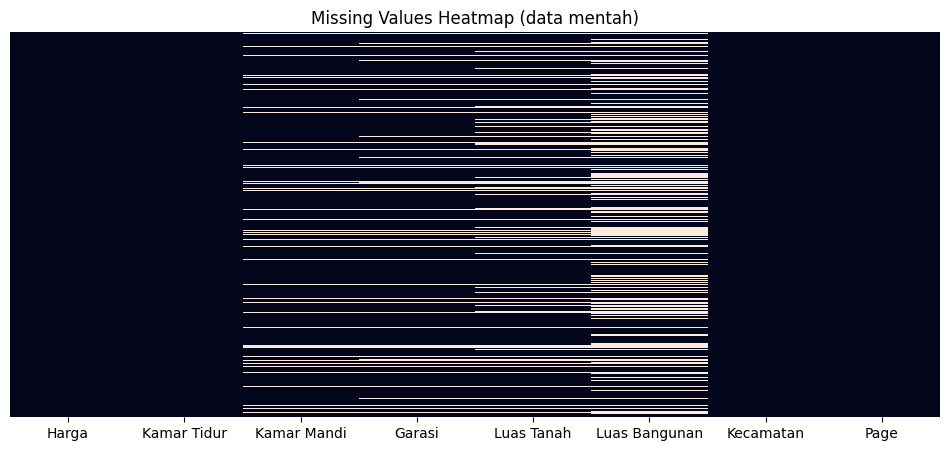

In [ ]:
plt.figure(figsize=(12, 5))
sns.heatmap(df_raw.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values Heatmap (data mentah)")
plt.show()

### A2. Duplikat identik
Duplikat identik = seluruh kolom (termasuk `Kecamatan` dan `Page`) sama persis dengan baris sebelumnya.

In [ ]:
n_dup = df_raw.duplicated().sum()
print("Jumlah duplikat identik:", n_dup)

Jumlah duplikat identik: 1525


### A3. Baris berlabel "Total" di kolom Harga
Label "Total" menandakan harga borongan untuk satu klaster/perumahan, bukan harga satu rumah.

In [ ]:
mask_total = df_raw['Harga'].astype(str).str.contains('Total', case=False, na=False)
print('Jumlah baris "Total":', mask_total.sum())
df_raw[mask_total].head()

Jumlah baris "Total": 5950


,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
11,"5,3 Miliar Total",LT:1368 m²,NaN,NaN,NaN,NaN,Depok I,129
16,30 Miliar Total,LT:2520 m²,NaN,NaN,NaN,NaN,Depok II,129
26,"28,1 Juta Total",LT:12 m²,NaN,NaN,NaN,NaN,Depok I,130
30,"5,5 Miliar Total",4,LT:1050 m²,LB:650 m²,NaN,NaN,Depok I,130
32,"104,5 Miliar Total",LT:19000 m²,NaN,NaN,NaN,NaN,Cilodong,130


### A4. Pola format Harga
Angka diganti `N` agar semua variasi format terlihat. Format di luar `N Juta` / `N,N Miliar` perlu penanganan khusus.

In [ ]:
pola_harga = df_raw['Harga'].astype(str).str.replace(r'\d+', 'N', regex=True).value_counts()
display(pola_harga.to_frame('Jumlah'))

,Jumlah
Harga,
"N,N Miliar",17462
N Juta,13793
"N,N Miliar Total",3731
N Miliar,2800
N Miliar Total,1352
N Juta Total,683
"N,N Juta Total",124
"N,N Juta",79
"N,N Triliun Total",51


### A5. Pola pergeseran kolom (akibat scraping)
Setiap sel diklasifikasikan: `angka` (nilai wajar), `LT` (berisi "LT : ... m²"), `LB` (berisi "LB : ... m²"), atau `NaN`. Jika kolom `Kamar Tidur`/`Kamar Mandi`/`Garasi` berisi `LT`/`LB`, nilai itu bergeser dari kolom yang benar.

In [ ]:
def tipe_nilai(x):
  if pd.isna(x):
    return 'NaN'
  x = str(x).strip()
  if re.match(r'^LT\s*:', x):
    return 'LT'
  if re.match(r'^LB\s*:', x):
    return 'LB'
  if re.match(r'^\d+$', x):
    return 'angka'
  return 'lain'

tipe_df = df_raw[cols_rumah].apply(lambda s: s.map(tipe_nilai))
shift_table = tipe_df.apply(pd.Series.value_counts).T.fillna(0).astype(int)
display(shift_table)

n_shift = (tipe_df[['Kamar Tidur', 'Kamar Mandi', 'Garasi']].isin(['LT', 'LB'])).any(axis=1).sum()
print(f"Baris dengan LT/LB nyasar di Kamar Tidur/Kamar Mandi/Garasi: {n_shift} ({n_shift/len(df_raw)*100:.1f}%)")

,LB,LT,NaN,angka
Kamar Tidur,90,4851,9,35250
Kamar Mandi,782,1379,4403,33636
Garasi,2498,7906,5189,24607
Luas Tanah,7901,24600,7699,0
Luas Bangunan,24598,0,15602,0


Baris dengan LT/LB nyasar di Kamar Tidur/Kamar Mandi/Garasi: 15579 (38.8%)


### A6. Suspect value pada kolom teks

In [ ]:
suspects = ['?', '??', 'NA', 'N/A', 'na', 'None', 'null', 'Null', 'Unknown', 'UNK', '-', '--', ' ', 'Nan', 'XXX', 'unk']
for val in suspects:
  total = (df_raw == val).sum().sum()
  if total > 0:
    print(f"{val!r}: {total}")
print("Selesai (hanya nilai yang ditemukan yang dicetak)")

Selesai (hanya nilai yang ditemukan yang dicetak)


## B. Pemisahan Baris "Total" dan Pembersihan Duplikat

Urutan: pisahkan "Total" lebih dulu agar tidak ikut ke data modeling, lalu hapus duplikat identik.

### B1. Pisahkan baris "Total" ke dataframe tersendiri

In [ ]:
df_total = df_raw[mask_total].copy()
df_work = df_raw[~mask_total].copy()

print("Baris Total (dipisah)   :", len(df_total))
print("Baris listing individu  :", len(df_work))
print("Cek penjumlahan         :", len(df_total) + len(df_work), "==", len(df_raw))

Baris Total (dipisah)   : 5950
Baris listing individu  : 34250
Cek penjumlahan         : 40200 == 40200


### B2. Hapus duplikat identik

In [ ]:
dup_work = df_work.duplicated().sum()
dup_total = df_total.duplicated().sum()
print(f"Duplikat di listing individu: {dup_work}")
print(f"Duplikat di baris Total     : {dup_total}")
print(f"Jumlah keduanya             : {dup_work + dup_total} (harus sama dengan {n_dup})")

df_work = df_work.drop_duplicates().reset_index(drop=True)
df_total = df_total.drop_duplicates().reset_index(drop=True)

print("\nSisa listing individu bersih:", df_work.shape)
print("Sisa baris Total bersih     :", df_total.shape)

Duplikat di listing individu: 1312
Duplikat di baris Total     : 213
Jumlah keduanya             : 1525 (harus sama dengan 1525)

Sisa listing individu bersih: (32938, 8)
Sisa baris Total bersih     : (5737, 8)


### B3. Temuan tambahan: listing yang sama muncul di beberapa Kecamatan
Bukan duplikat identik (kolom `Kecamatan`/`Page` berbeda), tetapi atribut rumahnya sama persis. Ini perlu dipertimbangkan sebelum split train/test (lihat catatan di akhir).

In [ ]:
fitur_rumah = ['Harga'] + cols_rumah
n_near = df_work.duplicated(subset=fitur_rumah).sum()
print(f"Baris dengan atribut rumah sama persis (abaikan Kecamatan & Page): {n_near} ({n_near/len(df_work)*100:.1f}%)")

contoh = df_work[df_work.duplicated(subset=fitur_rumah, keep=False)].sort_values(fitur_rumah).head(9)
display(contoh)

Baris dengan atribut rumah sama persis (abaikan Kecamatan & Page): 9232 (28.0%)


,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
17228,1 Miliar,1,1,LB:45 m²,NaN,NaN,Margonda,1987
21444,1 Miliar,1,1,LB:45 m²,NaN,NaN,Margonda,1081
4103,1 Miliar,2,1,1,LT : 72 m²,LB : 45 m²,Cimanggis,1182
4367,1 Miliar,2,1,1,LT : 72 m²,LB : 45 m²,Cimanggis,1198
8568,1 Miliar,2,1,1,LT : 72 m²,LB : 45 m²,Cimanggis,1455
9113,1 Miliar,2,1,1,LT : 72 m²,LB : 45 m²,Cimanggis,1489
21524,1 Miliar,2,1,1,LT : 72 m²,LB : 45 m²,Depok II,1086
32775,1 Miliar,2,1,1,LT : 72 m²,LB : 45 m²,Cimanggis,902
4543,1 Miliar,2,1,1,LT : 84 m²,LB : 49 m²,Cinangka,1208


### B4. Ringkasan alur jumlah baris

In [ ]:
alur = pd.DataFrame({
    'Tahap': ['Data mentah', 'Baris "Total" (dipisah)', 'Listing individu sebelum dedup',
              'Duplikat identik dihapus', 'Listing individu bersih', 'Baris Total bersih (disimpan terpisah)'],
    'Jumlah baris': [len(df_raw), mask_total.sum(), (~mask_total).sum(),
                     dup_work, len(df_work), len(df_total)]
})
display(alur)

,Tahap,Jumlah baris
0,Data mentah,40200
1,"Baris ""Total"" (dipisah)",5950
2,Listing individu sebelum dedup,34250
3,Duplikat identik dihapus,1312
4,Listing individu bersih,32938
5,Baris Total bersih (disimpan terpisah),5737


## C. Parsing Harga (target)

Hanya kolom target yang diparsing di Part 1 supaya distribusinya bisa dilihat. Format `/m²`, `/ha`, dan `Hubungi Agen` **bukan** harga total satu rumah, jadi ditandai terpisah dan tidak dipakai sebagai target.

In [ ]:
MULTIPLIER = {'Triliun': 1e12, 'Miliar': 1e9, 'Juta': 1e6, 'Ribu': 1e3}

def parse_harga(teks):
  """Kembalikan (harga_rupiah, jenis). jenis: individu | per_satuan | hubungi_agen | tidak_terbaca"""
  s = str(teks).strip()
  if 'hubungi' in s.lower():
    return np.nan, 'hubungi_agen'
  if re.search(r'/\s*(m²|m2|ha)', s, flags=re.I):
    return np.nan, 'per_satuan'
  m = re.match(r'^([\d.,]+)\s*(Triliun|Miliar|Juta|Ribu)\b', s, flags=re.I)
  if not m:
    return np.nan, 'tidak_terbaca'
  angka = float(m.group(1).replace(',', '.'))
  return angka * MULTIPLIER[m.group(2).capitalize()], 'individu'

hasil = df_work['Harga'].apply(parse_harga)
df_work['Harga_Rp'] = hasil.str[0]
df_work['Harga_Jenis'] = hasil.str[1]

display(df_work['Harga_Jenis'].value_counts().to_frame('Jumlah'))

,Jumlah
Harga_Jenis,
individu,32841
per_satuan,56
hubungi_agen,41


Contoh format harga yang tidak dipakai sebagai target:

In [ ]:
display(df_work[df_work['Harga_Jenis'] != 'individu'][['Harga', 'Harga_Jenis', 'Luas Tanah', 'Kecamatan']].head(10))

,Harga,Harga_Jenis,Luas Tanah,Kecamatan
45,"5,35 Juta /m²",per_satuan,LB : 3000 m²,Cilodong
553,17 Juta /m²,per_satuan,NaN,Cinere
1142,3 Miliar /m²,per_satuan,NaN,Cibubur
1646,"5,3 Juta /m²",per_satuan,NaN,Sukmajaya
1759,13 Juta /m²,per_satuan,NaN,Pancoran Mas
2668,Hubungi Agen,hubungi_agen,NaN,Sukmajaya
2671,Hubungi Agen,hubungi_agen,NaN,Limo
2676,Hubungi Agen,hubungi_agen,NaN,Cinere
2680,Hubungi Agen,hubungi_agen,NaN,Cinere
2690,Hubungi Agen,hubungi_agen,NaN,Tapos


### Validasi parser: pastikan tidak ada format individu yang lolos jadi NaN

In [ ]:
print("Harga_Rp NaN pada jenis 'individu':", df_work.loc[df_work['Harga_Jenis'] == 'individu', 'Harga_Rp'].isna().sum())
print("Tidak terbaca:", (df_work['Harga_Jenis'] == 'tidak_terbaca').sum())

# data target yang dipakai untuk EDA harga
df_eda = df_work[df_work['Harga_Jenis'] == 'individu'].copy()
df_eda['Harga_Juta'] = df_eda['Harga_Rp'] / 1e6
print("Baris dengan harga individu valid:", len(df_eda))

Harga_Rp NaN pada jenis 'individu': 0
Tidak terbaca: 0
Baris dengan harga individu valid: 32841


## D. EDA Awal Target (Harga)

### Ringkasan statistik harga (dalam juta Rupiah)

In [ ]:
display(df_eda['Harga_Juta'].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame('Harga (juta Rp)'))
print("Skewness harga     :", round(df_eda['Harga_Rp'].skew(), 2))
print("Skewness log1p     :", round(np.log1p(df_eda['Harga_Rp']).skew(), 2))

,Harga (juta Rp)
count,"32,841.00"
mean,"3,084.44"
std,"27,198.08"
min,0.00
1%,125.00
5%,295.00
25%,749.00
50%,"1,300.00"
75%,"2,700.00"
95%,"7,850.00"


Skewness harga     : 45.61
Skewness log1p     : -0.45


### Distribusi harga: skala asli vs log1p
Harga cenderung right-skewed. Histogram skala asli dipotong di persentil 99 hanya agar bentuknya terlihat (data tidak dibuang).

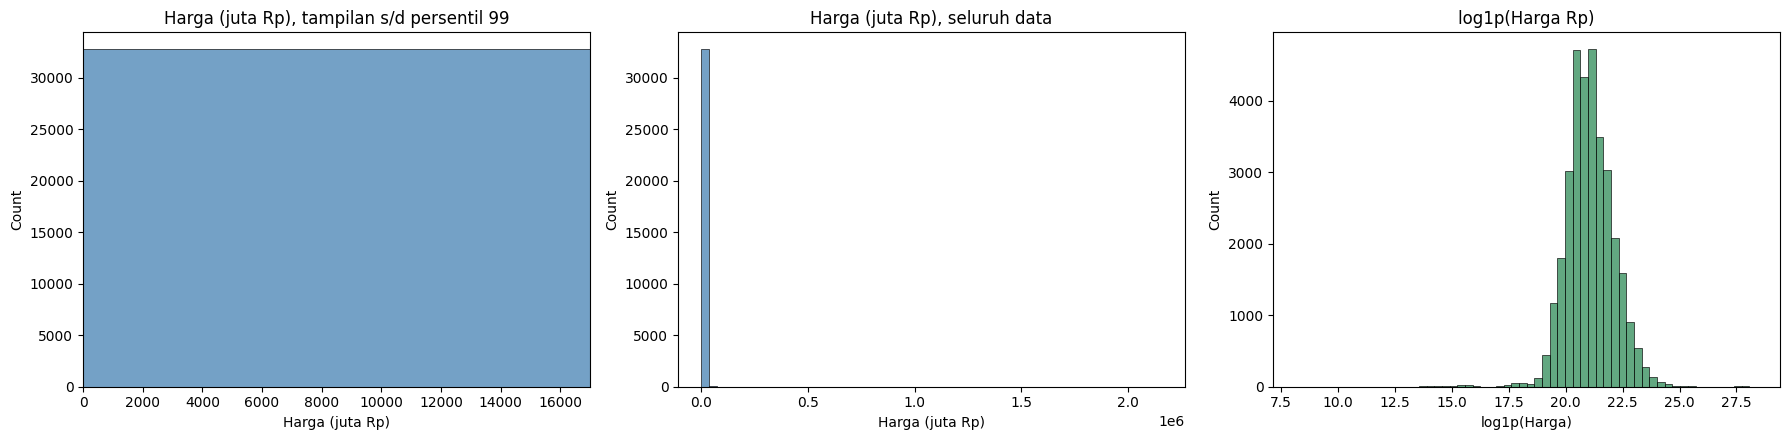

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

p99 = df_eda['Harga_Juta'].quantile(0.99)
sns.histplot(df_eda['Harga_Juta'], bins=60, ax=axes[0], color='steelblue')
axes[0].set_xlim(0, p99)
axes[0].set_title('Harga (juta Rp), tampilan s/d persentil 99')
axes[0].set_xlabel('Harga (juta Rp)')

sns.histplot(df_eda['Harga_Juta'], bins=60, ax=axes[1], color='steelblue')
axes[1].set_title('Harga (juta Rp), seluruh data')
axes[1].set_xlabel('Harga (juta Rp)')

sns.histplot(np.log1p(df_eda['Harga_Rp']), bins=60, ax=axes[2], color='seagreen')
axes[2].set_title('log1p(Harga Rp)')
axes[2].set_xlabel('log1p(Harga)')

plt.tight_layout()
plt.show()

### Boxplot harga (skala log)
Skala log dipakai agar rumah mewah tidak menekan visual. Titik di atas bukan otomatis salah; rumah puluhan miliar adalah data valid.

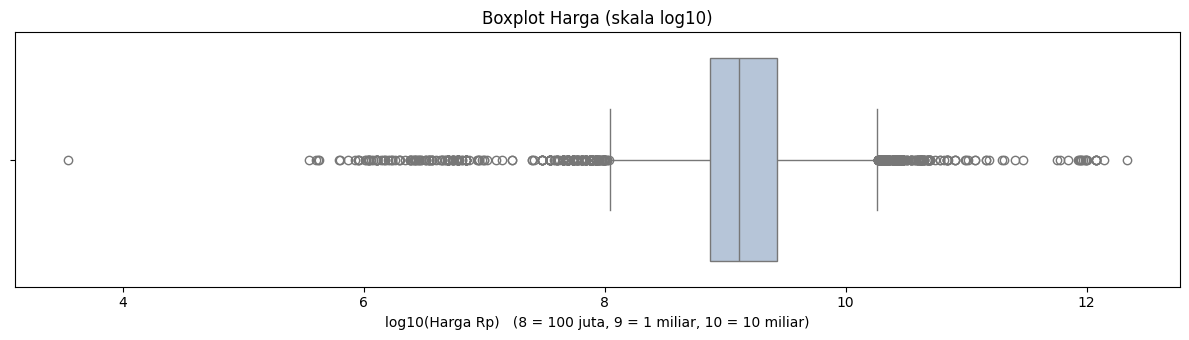

In [ ]:
plt.figure(figsize=(12, 3.5))
sns.boxplot(x=np.log10(df_eda['Harga_Rp']), color='lightsteelblue')
plt.xlabel('log10(Harga Rp)   (8 = 100 juta, 9 = 1 miliar, 10 = 10 miliar)')
plt.title('Boxplot Harga (skala log10)')
plt.tight_layout()
plt.show()

### Pemeriksaan batas logika properti (hanya dilaporkan, belum dibuang)
Pembuangan outlier berbasis domain knowledge (misal harga < Rp50 juta untuk rumah tapak) dikerjakan di Part 2 setelah luas tanah/bangunan direkonstruksi.

In [ ]:
batas_bawah = 50_000_000
print("Harga < Rp50 juta        :", (df_eda['Harga_Rp'] < batas_bawah).sum())
print("Harga >= Rp10 miliar     :", (df_eda['Harga_Rp'] >= 10e9).sum())
print("Harga >= Rp50 miliar     :", (df_eda['Harga_Rp'] >= 50e9).sum())
print("Harga >= Rp1 triliun     :", (df_eda['Harga_Rp'] >= 1e12).sum())

display(df_eda[df_eda['Harga_Rp'] < batas_bawah][['Harga', 'Kamar Tidur', 'Kamar Mandi', 'Luas Tanah', 'Luas Bangunan', 'Kecamatan']].head(10))
display(df_eda[df_eda['Harga_Rp'] >= 1e12][['Harga', 'Kamar Tidur', 'Kamar Mandi', 'Luas Tanah', 'Luas Bangunan', 'Kecamatan']].head(10))

Harga < Rp50 juta        : 184
Harga >= Rp10 miliar     : 1078
Harga >= Rp50 miliar     : 47
Harga >= Rp1 triliun     : 7


,Harga,Kamar Tidur,Kamar Mandi,Luas Tanah,Luas Bangunan,Kecamatan
491,"4,3 Juta",LT:6000 m²,NaN,NaN,NaN,Bojong Sari
645,"2,4 Juta",1,1,NaN,NaN,Cinere
1034,"12,5 Juta",5,2,LT : 3900 m²,LB : 400 m²,Cinere
1479,49 Juta,2,1,LT : 60 m²,LB : 36 m²,Citayam
2172,45 Juta,3,2,LT : 134 m²,LB : 100 m²,Cilodong
2205,"6,5 Juta",LT:1440 m²,NaN,NaN,NaN,Cinere
2529,"3,7 Juta",LT:11 m²,NaN,NaN,NaN,Depok II
3036,40 Juta,3,3,LT : 55 m²,LB : 60 m²,Cipayung
3419,45 Juta,2,1,LT : 68 m²,LB : 36 m²,Citayam
3671,6 Juta,3,3,LT : 100 m²,LB : 100 m²,Depok I


,Harga,Kamar Tidur,Kamar Mandi,Luas Tanah,Luas Bangunan,Kecamatan
2622,"1,4 Triliun",91,LT:92000 m²,NaN,NaN,Margonda
13749,"1,2 Triliun",1,LT:101 m²,NaN,NaN,Margonda
13812,"1,2 Triliun",91,LT:90140 m²,NaN,NaN,Margonda
15696,"2,16 Triliun",91,LT:91400 m²,NaN,NaN,Margonda
20082,"1,2 Triliun",91,LT:91400 m²,NaN,NaN,Margonda
22699,"1,2 Triliun",91,LT:91400 m²,NaN,NaN,Depok I
24954,"1,2 Triliun",91,LT:91400 m²,NaN,NaN,Margonda


### Distribusi Kecamatan

Jumlah Kecamatan unik: 37


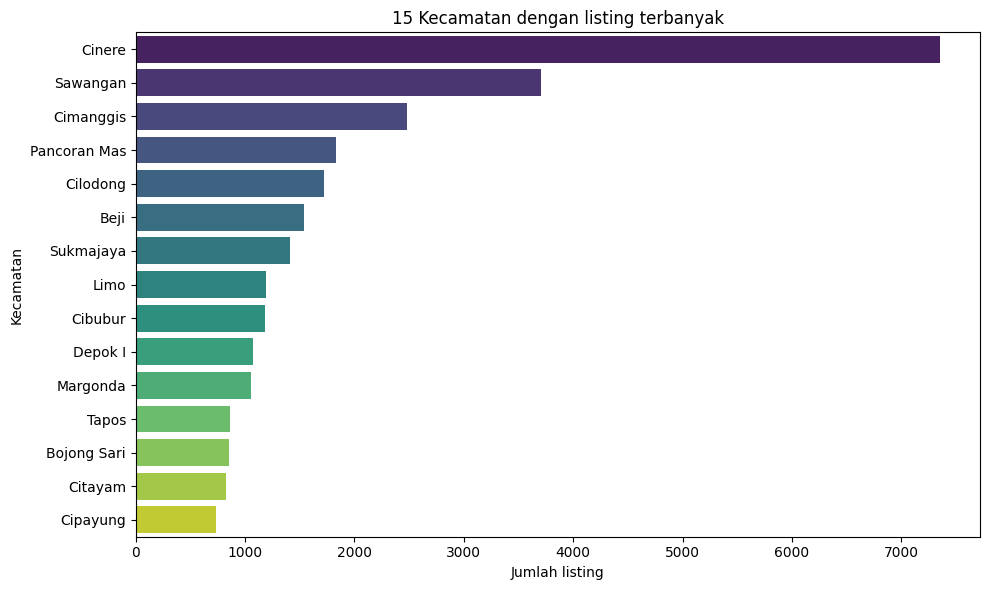

Kecamatan,Cinere,Sawangan,Cimanggis,Pancoran Mas,Cilodong,Beji,Sukmajaya,Limo,Cibubur,Depok I,Margonda,Tapos,Bojong Sari,Citayam,Cipayung,Pangkalan Jati,Harjamukti,Depok II,Cinangka,Tanah Baru,Rangkapanjaya,Kukusan,Kelapa Dua,Gandul,Pasir Putih,Krukut,Cisalak,Cilangkap,Mekarsari,Sukatani,Tugu,Tirtajaya,Grand Depok City,Ciangsana,Studio Alam,Kalimanggis,Babadan
Jumlah,7352,3704,2481,1831,1721,1539,1406,1195,1184,1075,1054,863,849,827,736,645,566,546,540,419,328,325,285,284,213,201,129,115,104,99,78,66,51,12,11,4,3


In [ ]:
print("Jumlah Kecamatan unik:", df_eda['Kecamatan'].nunique())

top_kec = df_eda['Kecamatan'].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=top_kec.values[:15], y=top_kec.index[:15], palette='viridis')
plt.title('15 Kecamatan dengan listing terbanyak')
plt.xlabel('Jumlah listing')
plt.tight_layout()
plt.show()

display(top_kec.to_frame('Jumlah').T)

### Harga per Kecamatan (median, 10 Kecamatan terbanyak)

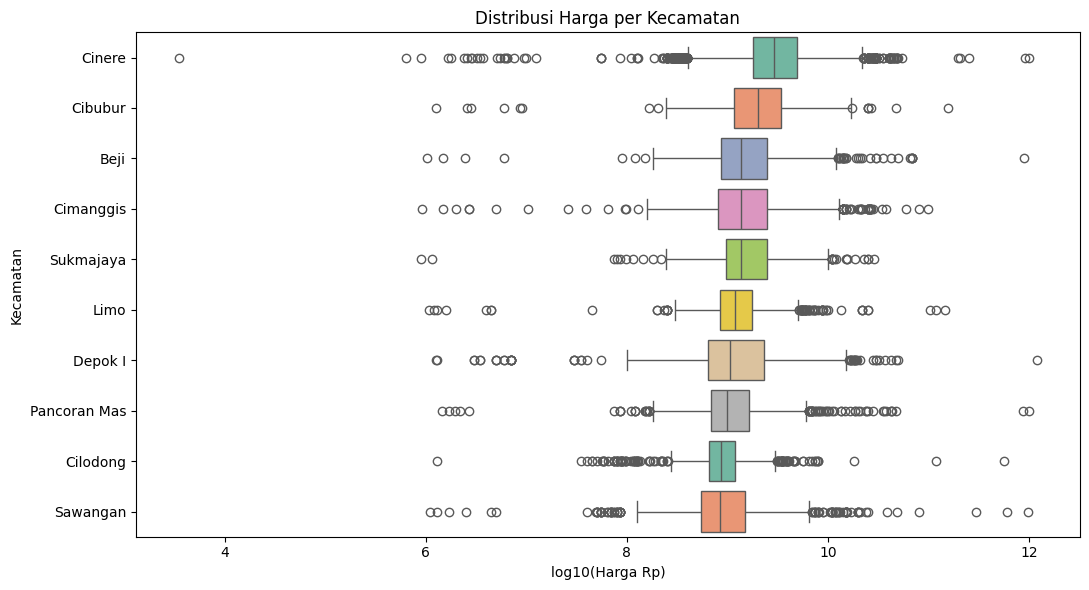

,count,median,mean
Kecamatan,,,
Cinere,7352,"2,900.00","4,446.60"
Cibubur,1184,"2,000.00","3,068.90"
Beji,1539,"1,350.00","3,151.70"
Cimanggis,2481,"1,350.00","2,327.80"
Sukmajaya,1406,"1,350.00","2,074.10"
Limo,1195,"1,190.00","1,989.10"
Depok I,1075,"1,070.00","3,433.40"
Pancoran Mas,1831,"1,000.00","2,670.30"
Cilodong,1721,860.00,"1,426.40"


In [ ]:
top10 = top_kec.index[:10]
df_top = df_eda[df_eda['Kecamatan'].isin(top10)]
urut = df_top.groupby('Kecamatan')['Harga_Rp'].median().sort_values(ascending=False).index

plt.figure(figsize=(11, 6))
sns.boxplot(data=df_top, y='Kecamatan', x=np.log10(df_top['Harga_Rp']), order=urut, palette='Set2')
plt.xlabel('log10(Harga Rp)')
plt.title('Distribusi Harga per Kecamatan')
plt.tight_layout()
plt.show()

display((df_top.groupby('Kecamatan')['Harga_Juta'].agg(['count', 'median', 'mean']).loc[urut]).round(1))

## E. Tabel Temuan Kualitas Data

In [ ]:
temuan = pd.DataFrame([
  ['Baris mentah', len(df_raw), 'Dasar audit'],
  ['Missing: Kamar Tidur / Kamar Mandi / Garasi', f"{df_raw['Kamar Tidur'].isna().sum()} / {df_raw['Kamar Mandi'].isna().sum()} / {df_raw['Garasi'].isna().sum()}", 'Sebagian besar akibat pergeseran kolom, bukan data hilang sungguhan'],
  ['Missing: Luas Tanah / Luas Bangunan', f"{df_raw['Luas Tanah'].isna().sum()} / {df_raw['Luas Bangunan'].isna().sum()}", 'Nilai LT/LB banyak bergeser ke kolom lain; rekonstruksi di Part 2'],
  ['Duplikat identik', n_dup, 'Dihapus (B2)'],
  ['Baris "Total" (klaster)', int(mask_total.sum()), 'Dipisah ke df_total, tidak untuk modeling'],
  ['Baris dengan LT/LB nyasar di KT/KM/Garasi', int(n_shift), 'Perlu parser regex (Part 2)'],
  ['Harga non-individu (/m², /ha, Hubungi Agen)', int((df_work['Harga_Jenis'] != 'individu').sum()), 'Tidak dipakai sebagai target'],
  ['Listing identik antar-Kecamatan (abaikan Kecamatan & Page)', int(n_near), 'Risiko leakage saat split; keputusan di Part 2'],
  ['Harga < Rp50 juta', int((df_eda['Harga_Rp'] < batas_bawah).sum()), 'Kandidat dibuang di Part 2 (batas domain)'],
], columns=['Temuan', 'Jumlah', 'Keterangan'])
display(temuan)

,Temuan,Jumlah,Keterangan
0,Baris mentah,40200,Dasar audit
1,Missing: Kamar Tidur / Kamar Mandi / Garasi,9 / 4403 / 5189,"Sebagian besar akibat pergeseran kolom, bukan ..."
2,Missing: Luas Tanah / Luas Bangunan,7699 / 15602,Nilai LT/LB banyak bergeser ke kolom lain; rek...
3,Duplikat identik,1525,Dihapus (B2)
4,"Baris ""Total"" (klaster)",5950,"Dipisah ke df_total, tidak untuk modeling"
5,Baris dengan LT/LB nyasar di KT/KM/Garasi,15579,Perlu parser regex (Part 2)
6,"Harga non-individu (/m², /ha, Hubungi Agen)",97,Tidak dipakai sebagai target
7,Listing identik antar-Kecamatan (abaikan Kecam...,9232,Risiko leakage saat split; keputusan di Part 2
8,Harga < Rp50 juta,184,Kandidat dibuang di Part 2 (batas domain)


## Catatan menuju Part 2
1. **Rekonstruksi kolom** dengan regex: nilai `LT : ... m²` / `LB : ... m²` yang nyasar di kolom lain dikembalikan ke tempatnya *sebelum* imputasi.
2. **Listing kembar antar-Kecamatan** (temuan B3): split train/test dan Cross-Validation memakai **grup listing** supaya listing yang sama tidak ada di train dan test sekaligus. Data tidak dibuang.
3. **Outlier:** batas domain properti (harga < Rp50 juta dan nilai mustahil), bukan IQR. Rumah mewah dipertahankan.
4. **Target:** `log1p(Harga)` di Part 4; evaluasi akhir dikembalikan ke Rupiah dengan `expm1`.

## Ringkasan Part 1 dan rencana lanjutan
Part 1 menyisakan `df_work` (listing individu, bersih dari duplikat identik) dan `df_total` (klaster, terpisah). Part 2 memperbaiki isi kolomnya, menyaring data tidak logis, lalu menyiapkan data untuk modeling.

# Part 2 — Rekonstruksi Kolom, Filter Domain, dan Persiapan Imputasi

**Alur Part 2:**
1. Parser regex mengembalikan nilai yang bergeser ke kolom yang benar.
2. Validasi hasil parser (uji kasus dan pengecekan asumsi).
3. Filter logika properti (batas domain), bukan IQR.
4. Standarisasi nama `Kecamatan`.
5. Strategi imputasi, lalu simpan data bersih.

**Catatan tentang imputasi:** nilai median/modus harus dihitung dari data train saja. Karena itu imputasi statistik (`SimpleImputer`) dipasang **di dalam Pipeline** pada Part 3 dan Part 4. Di Part 2 hanya ada pengisian yang berbasis aturan domain (tanpa belajar dari data), yaitu `Garasi` kosong menjadi 0.

## 2.1 Parser Regex untuk Pergeseran Kolom

Hasil scraping menyimpan nilai **tersusun rapat ke kiri**: bila sebuah atribut tidak ada, atribut sesudahnya naik ke kolom sebelumnya. Contoh baris asli:

| Kamar Tidur | Kamar Mandi | Garasi | Luas Tanah | Luas Bangunan | arti sebenarnya |
|---|---|---|---|---|---|
| 2 | 1 | `LB:41 m²` | NaN | NaN | KT=2, KM=1, tanpa garasi, tanpa LT, LB=41 |
| 3 | 2 | `LT:409 m²` | `LB : 300 m²` | NaN | KT=3, KM=2, tanpa garasi, LT=409, LB=300 |

Aturan parser:
- Sel berawalan `LT :` atau `LB :` dikenali dari teksnya, di kolom mana pun letaknya.
- Sel berisi angka murni dikumpulkan **berurutan** lalu diisikan ke `Kamar Tidur`, `Kamar Mandi`, `Garasi` (urutan susunan rapat kiri).
- Format lain ditandai sebagai `format_tak_dikenal` dan dilaporkan.

In [ ]:
RE_LT = re.compile(r'^\s*LT\s*:\s*(\d+(?:[.,]\d+)?)\s*m\s*[²2]?\s*$', re.IGNORECASE)
RE_LB = re.compile(r'^\s*LB\s*:\s*(\d+(?:[.,]\d+)?)\s*m\s*[²2]?\s*$', re.IGNORECASE)
RE_ANGKA = re.compile(r'^\s*(\d+)\s*$')

def parse_luas(teks):
  """Kembalikan (label, nilai) bila teks berformat 'LT : 100 m²' / 'LB : 80 m²', selain itu None."""
  for label, pola in (('LT', RE_LT), ('LB', RE_LB)):
    m = pola.match(teks)
    if m:
      return label, float(m.group(1).replace(',', '.'))
  return None

def rekonstruksi_baris(nilai_sel):
  """nilai_sel: isi lima kolom rumah (urutan asli). Hasil: atribut yang sudah ditempatkan benar."""
  angka, luas, status = [], {}, 'ok'
  for sel in nilai_sel:
    if pd.isna(sel):
      continue
    teks = str(sel).strip()
    hasil = parse_luas(teks)
    if hasil is not None:
      label, nilai = hasil
      if label in luas:
        status = 'konflik_luas'      # label ganda: pakai nilai pertama
      else:
        luas[label] = nilai
    elif RE_ANGKA.match(teks):
      angka.append(int(teks))
    else:
      status = 'format_tak_dikenal'
  n_angka = len(angka)
  if n_angka > 3:
    status = 'angka_berlebih'
  angka = (angka + [np.nan] * 3)[:3]
  return {'Kamar_Tidur': angka[0], 'Kamar_Mandi': angka[1], 'Garasi': angka[2],
          'Luas_Tanah': luas.get('LT', np.nan), 'Luas_Bangunan': luas.get('LB', np.nan),
          'n_angka': n_angka, 'status': status}

### Uji kasus parser
Contoh nyata dari data (termasuk baris yang bergeser) harus menghasilkan nilai yang benar.

In [ ]:
t1 = rekonstruksi_baris(['2', '1', 'LB:41 m²', np.nan, np.nan])
assert (t1['Kamar_Tidur'], t1['Kamar_Mandi'], t1['Luas_Bangunan']) == (2, 1, 41.0)
assert pd.isna(t1['Garasi']) and pd.isna(t1['Luas_Tanah'])

t2 = rekonstruksi_baris(['3', '2', 'LT:409 m²', 'LB : 300 m²', np.nan])
assert (t2['Luas_Tanah'], t2['Luas_Bangunan']) == (409.0, 300.0) and pd.isna(t2['Garasi'])

t3 = rekonstruksi_baris(['4', '3', '10', 'LT : 438 m²', 'LB : 110 m²'])
assert (t3['Kamar_Tidur'], t3['Kamar_Mandi'], t3['Garasi'], t3['Luas_Tanah'], t3['Luas_Bangunan']) == (4, 3, 10, 438.0, 110.0)

t4 = rekonstruksi_baris(['LT:260 m²', np.nan, np.nan, np.nan, np.nan])
assert t4['Luas_Tanah'] == 260.0 and pd.isna(t4['Kamar_Tidur'])
print("Semua uji kasus parser lolos")

Semua uji kasus parser lolos


### Terapkan parser ke seluruh listing individu

In [ ]:
rekon = pd.DataFrame(
    [rekonstruksi_baris(r) for r in df_work[cols_rumah].itertuples(index=False)],
    index=df_work.index
)

print("Status parsing:")
display(rekon['status'].value_counts().to_frame('Jumlah'))

fitur_num = ['Kamar_Tidur', 'Kamar_Mandi', 'Garasi', 'Luas_Tanah', 'Luas_Bangunan']
sebelum = df_work[cols_rumah].isna().sum()
sebelum.index = fitur_num
sesudah = rekon[fitur_num].isna().sum()
tabel_missing = pd.DataFrame({
    'Kosong sebelum (posisi kolom asli)': sebelum,
    'Kosong sesudah rekonstruksi': sesudah,
})
tabel_missing['Persen sesudah (%)'] = (tabel_missing['Kosong sesudah rekonstruksi'] / len(df_work) * 100).round(2)
display(tabel_missing)

Status parsing:


,Jumlah
status,
ok,32938


,Kosong sebelum (posisi kolom asli),Kosong sesudah rekonstruksi,Persen sesudah (%)
Kamar_Tidur,3,483,1.47
Kamar_Mandi,221,881,2.67
Garasi,719,9370,28.45
Luas_Tanah,1966,1407,4.27
Luas_Bangunan,9379,147,0.45


### Cek asumsi susunan rapat kiri
Jika asumsi benar, nilai tengah `Kamar Mandi` pada baris dengan 2 angka dan baris dengan 3 angka harus mirip, dan `Garasi` yang tercatat tidak pernah 0 (garasi hanya dicantumkan bila ada).

In [ ]:
display(rekon.groupby('n_angka')[['Kamar_Tidur', 'Kamar_Mandi', 'Garasi']].median())
print("Nilai Garasi terkecil yang tercatat:", rekon['Garasi'].min())

,Kamar_Tidur,Kamar_Mandi,Garasi
n_angka,,,
0,NaN,NaN,NaN
1,1.00,NaN,NaN
2,3.00,2.00,NaN
3,3.00,2.00,1.00


Nilai Garasi terkecil yang tercatat: 1.0


### Contoh baris sebelum dan sesudah rekonstruksi

In [ ]:
contoh_idx = df_work[df_work[cols_rumah].apply(lambda s: s.map(tipe_nilai)).isin(['LT', 'LB']).iloc[:, :3].any(axis=1)].index[:6]
display(df_work.loc[contoh_idx, cols_rumah])
display(rekon.loc[contoh_idx, fitur_num])

,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan
5,2,1,LB:41 m²,NaN,NaN
6,3,2,LT:409 m²,LB : 300 m²,NaN
7,4,3,LT:280 m²,LB : 240 m²,NaN
10,1,1,LB:25 m²,NaN,NaN
11,3,3,LT:128 m²,LB : 138 m²,NaN
13,3,2,LB:73 m²,NaN,NaN


,Kamar_Tidur,Kamar_Mandi,Garasi,Luas_Tanah,Luas_Bangunan
5,2.00,1.00,NaN,NaN,41.00
6,3.00,2.00,NaN,409.00,300.00
7,4.00,3.00,NaN,280.00,240.00
10,1.00,1.00,NaN,NaN,25.00
11,3.00,3.00,NaN,128.00,138.00
13,3.00,2.00,NaN,NaN,73.00


## 2.2 Susun dataframe kerja
Garasi yang kosong diisi 0 (aturan domain, bukan statistik).

In [ ]:
df_p = pd.concat(
    [df_work[['Harga', 'Harga_Rp', 'Harga_Jenis', 'Kecamatan', 'Page']], rekon[fitur_num]],
    axis=1
)
df_p['Garasi'] = df_p['Garasi'].fillna(0)
print(df_p.shape)
df_p.head()

(32938, 10)


,Harga,Harga_Rp,Harga_Jenis,Kecamatan,Page,Kamar_Tidur,Kamar_Mandi,Garasi,Luas_Tanah,Luas_Bangunan
0,"2,5 Miliar","2,500,000,000.00",individu,Tapos,129,4.00,3.00,10.00,438.00,110.00
1,385 Juta,"385,000,000.00",individu,Pancoran Mas,129,3.00,2.00,1.00,50.00,60.00
2,385 Juta,"385,000,000.00",individu,Cipayung,129,3.00,2.00,1.00,50.00,60.00
3,385 Juta,"385,000,000.00",individu,Rangkapanjaya,129,3.00,2.00,1.00,50.00,60.00
4,950 Juta,"950,000,000.00",individu,Sawangan,129,2.00,1.00,1.00,87.00,50.00


## 2.3 Filter Logika Properti (Batas Domain)

IQR tidak dipakai karena rumah mewah puluhan miliar adalah data valid. Yang dibuang hanya data yang **tidak mungkin** untuk rumah tapak:

| Aturan | Alasan |
|---|---|
| Harga bukan harga satu rumah | `/m²`, `/ha`, `Hubungi Agen` |
| Harga < Rp50 juta | tidak logis untuk rumah tapak |
| Kamar tidur atau kamar mandi > 12 | kemungkinan kos/gedung atau salah scrape (nilai 91, 284, dst.) |
| Garasi > 10 | tidak wajar untuk satu rumah |
| LT di luar 15–10.000 m² atau LB di luar 15–5.000 m² | nilai mustahil (mis. LT = 1 m², LT = 818 juta m²) |
| Rasio LB/LT > 6 | bangunan 6x lebih luas dari tanahnya tidak mungkin |
| Harga per m² (tanah atau bangunan) di luar Rp0,5–100 juta | salah ketik nominal (mis. rumah 60 m² seharga Rp104 miliar) |
| LT dan LB sama-sama kosong | tidak ada informasi ukuran sama sekali |

Rumah mewah dengan harga tinggi **tetap dipertahankan** selama harga per m²-nya masuk akal.

In [ ]:
BATAS = {
    'harga_min': 50_000_000,
    'kamar_maks': 12,
    'garasi_maks': 10,
    'lt_rentang': (15, 10_000),
    'lb_rentang': (15, 5_000),
    'rasio_lb_lt_maks': 6,
    'harga_per_m2_rentang': (0.5e6, 100e6),
}

lt, lb, harga = df_p['Luas_Tanah'], df_p['Luas_Bangunan'], df_p['Harga_Rp']
rasio = lb / lt
hpm_lt = harga / lt
hpm_lb = harga / lb
lo, hi = BATAS['harga_per_m2_rentang']

aturan = {
    'Harga bukan harga satu rumah (/m², /ha, Hubungi Agen)': df_p['Harga_Jenis'] != 'individu',
    f"Harga < Rp{BATAS['harga_min']/1e6:,.0f} juta": harga < BATAS['harga_min'],
    f"Kamar tidur atau kamar mandi > {BATAS['kamar_maks']}": (df_p['Kamar_Tidur'] > BATAS['kamar_maks']) | (df_p['Kamar_Mandi'] > BATAS['kamar_maks']),
    f"Garasi > {BATAS['garasi_maks']}": df_p['Garasi'] > BATAS['garasi_maks'],
    f"LT di luar {BATAS['lt_rentang'][0]}-{BATAS['lt_rentang'][1]:,} m²": lt.notna() & ~lt.between(*BATAS['lt_rentang']),
    f"LB di luar {BATAS['lb_rentang'][0]}-{BATAS['lb_rentang'][1]:,} m²": lb.notna() & ~lb.between(*BATAS['lb_rentang']),
    f"Rasio LB/LT > {BATAS['rasio_lb_lt_maks']}": rasio > BATAS['rasio_lb_lt_maks'],
    f"Harga per m² di luar Rp{lo/1e6:.1f}-{hi/1e6:.0f} juta": (hpm_lt < lo) | (hpm_lt > hi) | (hpm_lb < lo) | (hpm_lb > hi),
    'LT dan LB sama-sama kosong': lt.isna() & lb.isna(),
}

ringkas = pd.DataFrame({'Baris terkena aturan': {k: int(v.sum()) for k, v in aturan.items()}})
display(ringkas)

dibuang = np.logical_or.reduce(list(aturan.values()))
print(f"Total baris dibuang (gabungan, tanpa hitung ganda): {dibuang.sum()}")
print(f"Baris sebelum filter : {len(df_p)}")
print(f"Baris setelah filter : {(~dibuang).sum()}")

,Baris terkena aturan
"Harga bukan harga satu rumah (/m², /ha, Hubungi Agen)",97
Harga < Rp50 juta,184
Kamar tidur atau kamar mandi > 12,465
Garasi > 10,93
"LT di luar 15-10,000 m²",54
"LB di luar 15-5,000 m²",41
Rasio LB/LT > 6,27
Harga per m² di luar Rp0.5-100 juta,263
LT dan LB sama-sama kosong,13


Total baris dibuang (gabungan, tanpa hitung ganda): 951
Baris sebelum filter : 32938
Baris setelah filter : 31987


In [ ]:
df_clean = df_p[~dibuang].copy().reset_index(drop=True)
df_buang = df_p[dibuang].copy()

print("Contoh baris yang dibuang:")
display(df_buang[['Harga', 'Kamar_Tidur', 'Kamar_Mandi', 'Garasi', 'Luas_Tanah', 'Luas_Bangunan', 'Kecamatan']].sample(10, random_state=SEED))

Contoh baris yang dibuang:


,Harga,Kamar_Tidur,Kamar_Mandi,Garasi,Luas_Tanah,Luas_Bangunan,Kecamatan
7582,80 Miliar,NaN,NaN,0.00,"10,286.00","5,000.00",Sawangan
15291,14 Miliar,7.00,6.00,14.00,"1,060.00",630.00,Cibubur
22372,4 Miliar,28.00,7.00,0.00,387.00,400.00,Depok II
24603,"1,4 Juta",NaN,NaN,0.00,552.00,NaN,Bojong Sari
17544,"2,7 Juta",3.00,3.00,1.00,145.00,160.00,Pancoran Mas
20226,"4,6 Miliar",13.00,14.00,0.00,300.00,750.00,Depok I
27735,14 Miliar,7.00,6.00,14.00,"1,060.00",630.00,Cibubur
17566,915 Ribu,3.00,2.00,1.00,50.00,72.00,Cimanggis
32106,6 Juta,3.00,2.00,1.00,80.00,100.00,Depok I
6571,13 Juta /m²,2.00,NaN,0.00,"1,500.00",300.00,Cimanggis


### Dampak filter pada distribusi harga
Rumah mewah tetap ada (ekor kanan dipertahankan).

In [ ]:
perbandingan = pd.DataFrame({
    'Sebelum filter (juta Rp)': df_eda['Harga_Juta'].describe(percentiles=[.01, .5, .99]),
    'Setelah filter (juta Rp)': (df_clean['Harga_Rp'] / 1e6).describe(percentiles=[.01, .5, .99]),
})
display(perbandingan)
print("Harga tertinggi setelah filter:", f"Rp{df_clean['Harga_Rp'].max()/1e9:,.1f} miliar")
print("Listing >= Rp10 miliar yang dipertahankan:", (df_clean['Harga_Rp'] >= 10e9).sum())

,Sebelum filter (juta Rp),Setelah filter (juta Rp)
count,"32,841.00","31,987.00"
mean,"3,084.44","2,265.41"
std,"27,198.08","3,152.28"
min,0.00,50.00
1%,125.00,185.00
50%,"1,300.00","1,300.00"
99%,"17,000.00","15,000.00"
max,"2,160,000.00","80,000.00"


Harga tertinggi setelah filter: Rp80.0 miliar
Listing >= Rp10 miliar yang dipertahankan: 858


## 2.4 Standarisasi Nama Kecamatan
Merapikan spasi dan kapitalisasi (`strip`, spasi ganda, `title`), angka romawi dijaga. Kategori yang sangat jarang tidak digabung di sini; penggabungan kategori langka dilakukan di dalam Pipeline (`min_frequency` pada encoder) supaya hanya bergantung pada data train.

In [ ]:
def standarisasi_kecamatan(nama):
  s = re.sub(r'\s+', ' ', str(nama).strip()).title()
  s = re.sub(r'\bIi\b', 'II', s)
  s = re.sub(r'\bIii\b', 'III', s)
  return s

sebelum_n = df_clean['Kecamatan'].nunique()
df_clean['Kecamatan'] = df_clean['Kecamatan'].apply(standarisasi_kecamatan)
print(f"Kecamatan unik: {sebelum_n} -> {df_clean['Kecamatan'].nunique()}")

kec_count = df_clean['Kecamatan'].value_counts()
print("Kecamatan dengan < 30 listing (kandidat digabung oleh encoder):")
display(kec_count[kec_count < 30].to_frame('Jumlah').T)

Kecamatan unik: 37 -> 37
Kecamatan dengan < 30 listing (kandidat digabung oleh encoder):


Kecamatan,Ciangsana,Studio Alam,Kalimanggis,Babadan
Jumlah,12,11,4,3


## 2.5 Strategi Imputasi dan Grup Listing

Sisa nilai kosong:

In [ ]:
sisa = df_clean[fitur_num + ['Kecamatan']].isnull().sum().to_frame('Kosong')
sisa['Persen (%)'] = (sisa['Kosong'] / len(df_clean) * 100).round(2)
display(sisa)

,Kosong,Persen (%)
Kamar_Tidur,371,1.16
Kamar_Mandi,711,2.22
Garasi,0,0.00
Luas_Tanah,1375,4.30
Luas_Bangunan,55,0.17
Kecamatan,0,0.00


| Fitur | Strategi (di dalam Pipeline, di-fit pada data train) |
|---|---|
| `Kamar_Tidur`, `Kamar_Mandi`, `Luas_Tanah`, `Luas_Bangunan` | median + kolom indikator "kosong" (`add_indicator=True`) |
| `Garasi` | sudah 0 untuk yang tidak dicantumkan (aturan domain di atas) |
| `Kecamatan` | modus (`most_frequent`) |

**Grup listing:** listing yang sama dapat muncul berulang (lintas halaman/Kecamatan). Kunci grup = harga + kamar + garasi + LT + LB. Dipakai untuk split dan Cross-Validation.

In [ ]:
kunci_grup = ['Harga_Rp', 'Kamar_Tidur', 'Kamar_Mandi', 'Garasi', 'Luas_Tanah', 'Luas_Bangunan']
df_clean['Grup_Listing'] = df_clean.groupby(kunci_grup, dropna=False).ngroup()

n_grup = df_clean['Grup_Listing'].nunique()
print(f"Jumlah baris : {len(df_clean)}")
print(f"Jumlah grup  : {n_grup}  (rata-rata {len(df_clean)/n_grup:.2f} baris per listing unik)")

Jumlah baris : 31987
Jumlah grup  : 22967  (rata-rata 1.39 baris per listing unik)


## 2.6 EDA setelah rekonstruksi

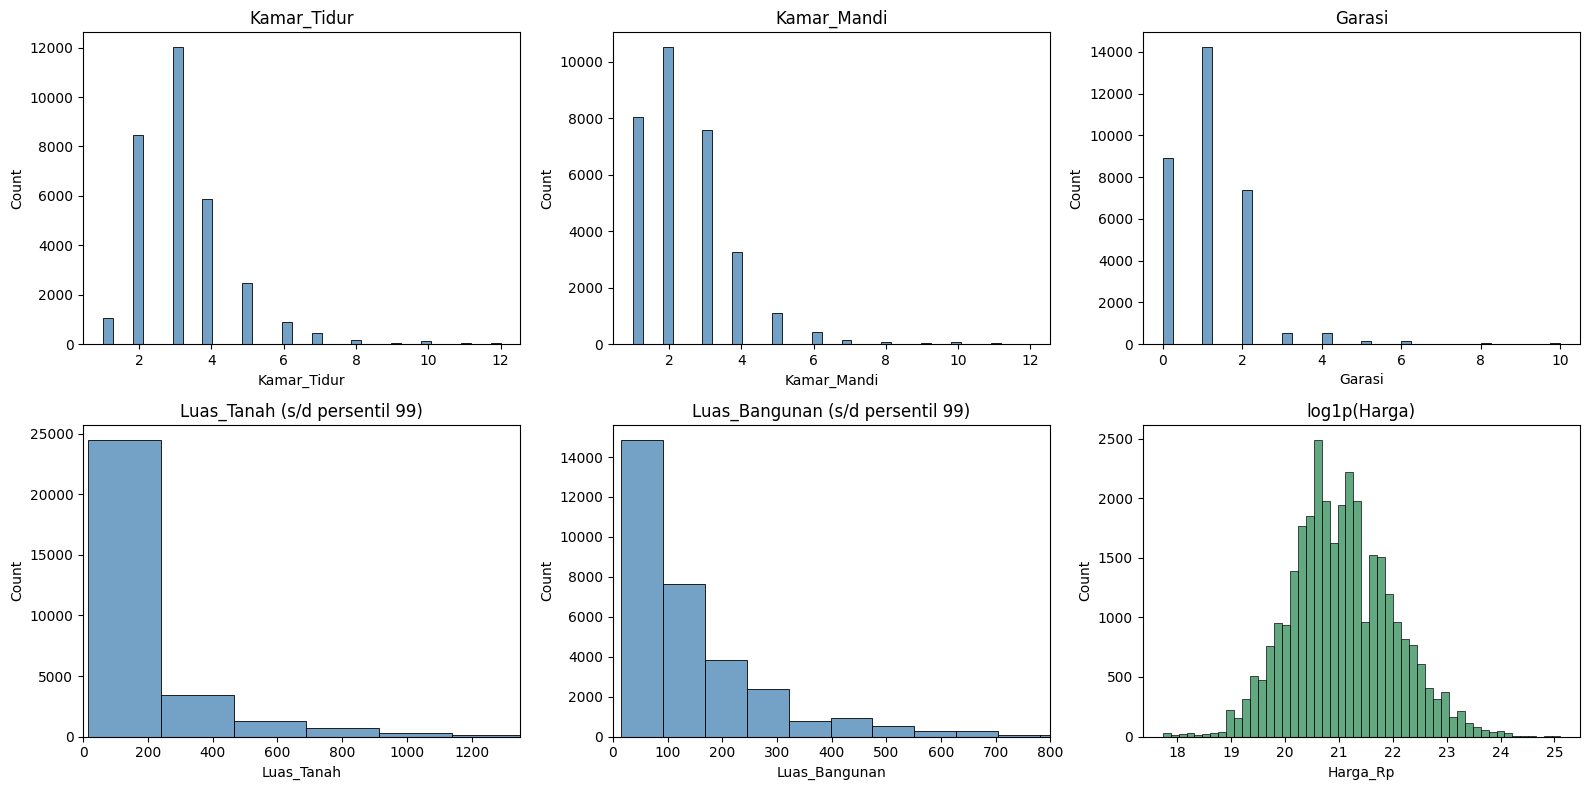

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel()[:5], fitur_num):
  sns.histplot(df_clean[col].dropna(), bins=40, ax=ax, color='steelblue')
  ax.set_title(col)
  if col in ('Luas_Tanah', 'Luas_Bangunan'):
    ax.set_xlim(0, df_clean[col].quantile(0.99))
    ax.set_title(col + ' (s/d persentil 99)')
sns.histplot(np.log1p(df_clean['Harga_Rp']), bins=50, ax=axes[1, 2], color='seagreen')
axes[1, 2].set_title('log1p(Harga)')
plt.tight_layout()
plt.show()

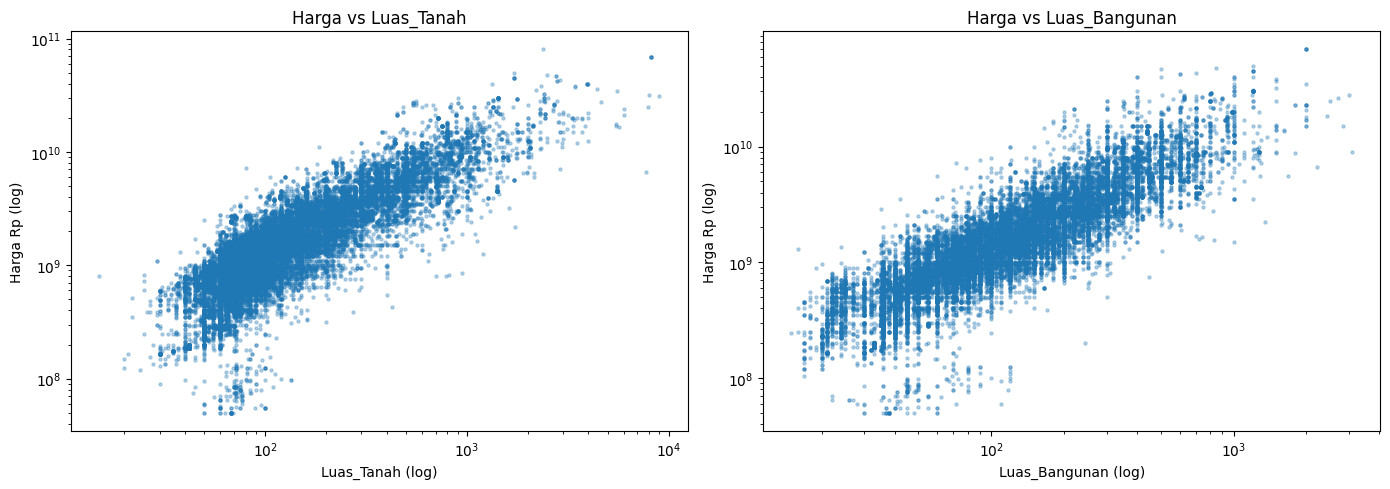

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ['Luas_Tanah', 'Luas_Bangunan']):
  ax.scatter(df_clean[col], df_clean['Harga_Rp'], s=5, alpha=0.3)
  ax.set_xscale('log')
  ax.set_yscale('log')
  ax.set_xlabel(col + ' (log)')
  ax.set_ylabel('Harga Rp (log)')
  ax.set_title(f'Harga vs {col}')
plt.tight_layout()
plt.show()

### Korelasi Spearman dengan Harga
Spearman dipilih karena hubungan harga dengan luas tidak linear dan distribusinya miring.

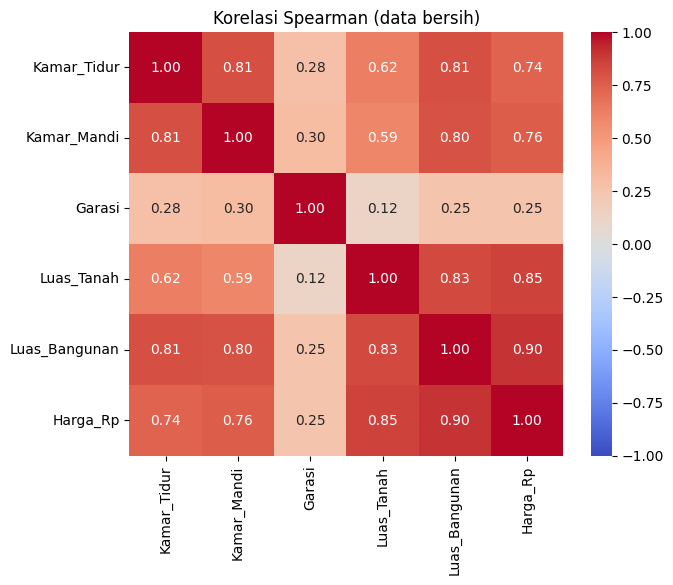

In [ ]:
korelasi = df_clean[fitur_num + ['Harga_Rp']].corr(method='spearman')
plt.figure(figsize=(7, 5.5))
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Korelasi Spearman (data bersih)')
plt.show()

### Harga per Kecamatan (data bersih)

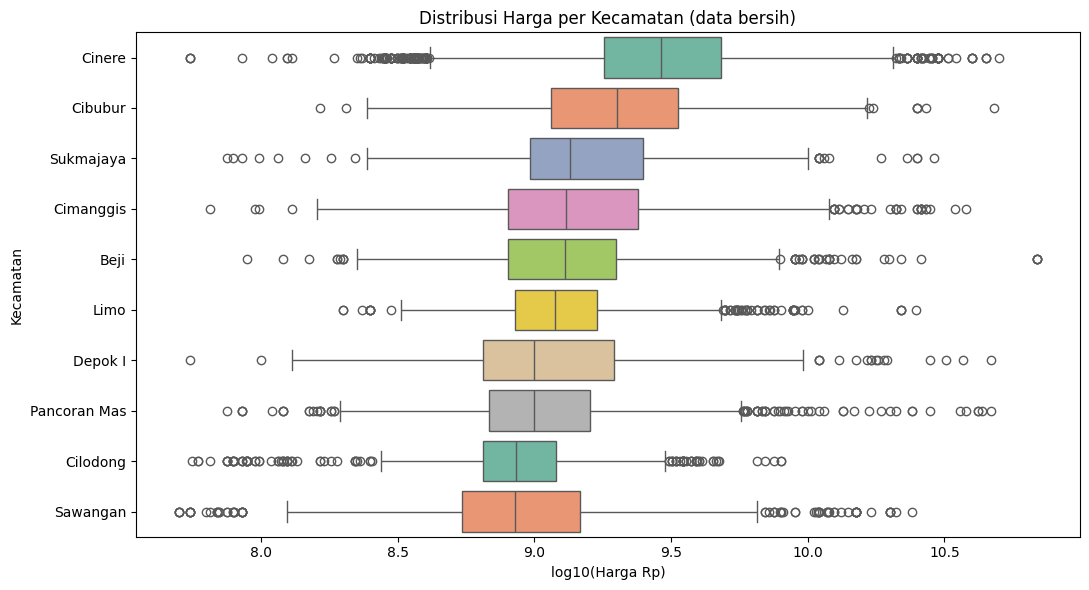

In [ ]:
top10 = df_clean['Kecamatan'].value_counts().index[:10]
df_top = df_clean[df_clean['Kecamatan'].isin(top10)]
urut = df_top.groupby('Kecamatan')['Harga_Rp'].median().sort_values(ascending=False).index

plt.figure(figsize=(11, 6))
sns.boxplot(data=df_top, y='Kecamatan', x=np.log10(df_top['Harga_Rp']), order=urut, palette='Set2')
plt.xlabel('log10(Harga Rp)')
plt.title('Distribusi Harga per Kecamatan (data bersih)')
plt.tight_layout()
plt.show()

## 2.7 Simpan data bersih

In [ ]:
kolom_simpan = ['Harga_Rp'] + fitur_num + ['Kecamatan', 'Grup_Listing']
df_clean[kolom_simpan].to_csv('rumah_bersih.csv', index=False)
df_total.to_csv('rumah_total_klaster.csv', index=False)

alur2 = pd.DataFrame({
    'Tahap': ['Data mentah',
              'Setelah baris "Total" dipisah',
              'Setelah duplikat identik dihapus (listing individu)',
              'Setelah filter domain = data bersih untuk modeling'],
    'Baris tersisa': [len(df_raw), int((~mask_total).sum()), len(df_work), len(df_clean)],
    'Baris keluar pada tahap ini': [0, int(mask_total.sum()), int(dup_work), int(dibuang.sum())],
})
display(alur2)
print("df_total (klaster) tersimpan terpisah:", df_total.shape, "-> tidak dipakai untuk model harga rumah individu")

,Tahap,Baris tersisa,Baris keluar pada tahap ini
0,Data mentah,40200,0
1,"Setelah baris ""Total"" dipisah",34250,5950
2,Setelah duplikat identik dihapus (listing indi...,32938,1312
3,Setelah filter domain = data bersih untuk mode...,31987,951


df_total (klaster) tersimpan terpisah: (5737, 8) -> tidak dipakai untuk model harga rumah individu


# Part 3 — Direct Modeling (Baseline)

Tujuan: menetapkan **tolok ukur awal** dengan perlakuan paling sederhana, lalu dibandingkan dengan Part 4 dan Part 5.

Perlakuan baseline:
- Split train/test **80:20**, berbasis grup listing (listing yang sama tidak terbelah ke dua sisi).
- Target dipakai apa adanya (Rupiah), tanpa transformasi.
- Nilai kosong diisi median di dalam `Pipeline` (hanya belajar dari train).
- `Kecamatan` diubah ke angka dengan `OrdinalEncoder` (cara paling sederhana; belum tepat untuk model linear, dan itu bagian dari alasan Part 4).
- 5 model dengan parameter default.

### Import library

In [ ]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

### Siapkan fitur dan target

In [ ]:
df_model = pd.read_csv('rumah_bersih.csv')

fitur_mentah = ['Kamar_Tidur', 'Kamar_Mandi', 'Garasi', 'Luas_Tanah', 'Luas_Bangunan', 'Kecamatan']
X = df_model[fitur_mentah]
y = df_model['Harga_Rp']
grup = df_model['Grup_Listing']

print("X:", X.shape, "| y:", y.shape)

X: (31987, 6) | y: (31987,)


### Splitting 80% : 20% (berbasis grup listing)

In [ ]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
idx_train, idx_test = next(gss.split(X, y, groups=grup))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train = grup.iloc[idx_train]

print(f"Train: {len(X_train)} baris ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test : {len(X_test)} baris ({len(X_test)/len(X)*100:.1f}%)")

# pastikan tidak ada listing yang sama di train dan test
overlap = set(grup.iloc[idx_train]) & set(grup.iloc[idx_test])
print("Grup listing yang muncul di train dan test:", len(overlap))
assert len(overlap) == 0

Train: 25509 baris (79.7%)
Test : 6478 baris (20.3%)
Grup listing yang muncul di train dan test: 0


### Cek distribusi target di train dan test

In [ ]:
dist = pd.DataFrame({'Train (juta Rp)': (y_train / 1e6).describe(percentiles=[.25, .5, .75, .95]),
                     'Test (juta Rp)': (y_test / 1e6).describe(percentiles=[.25, .5, .75, .95])})
display(dist)

,Train (juta Rp),Test (juta Rp)
count,"25,509.00","6,478.00"
mean,"2,262.01","2,278.80"
std,"3,063.67","3,479.57"
min,50.00,50.00
25%,750.00,725.00
50%,"1,300.00","1,270.00"
75%,"2,600.00","2,600.00"
95%,"7,500.00","7,000.00"
max,"80,000.00","69,000.00"


### Fungsi evaluasi
Semua model dinilai di **skala Rupiah**: MAE (Rp), MAPE (%), R², dan MdAPE (median persentase error, tahan terhadap harga ekstrem). Hasil dicatat di `hasil_eval` untuk perbandingan antar tahap.

In [ ]:
hasil_eval = []

def hitung_metrik(y_true, y_pred):
  y_true = np.asarray(y_true, dtype=float)
  y_pred = np.asarray(y_pred, dtype=float)
  ape = np.abs(y_true - y_pred) / np.abs(y_true)
  return {
      'MAE (Rp)': mean_absolute_error(y_true, y_pred),
      'MAPE (%)': mean_absolute_percentage_error(y_true, y_pred) * 100,
      'MdAPE (%)': np.median(ape) * 100,
      'R2': r2_score(y_true, y_pred),
  }

def evaluasi(tahap, nama, model, Xte, yte, cetak=True):
  pred = model.predict(Xte)
  m = hitung_metrik(yte, pred)
  hasil_eval.append({'Tahap': tahap, 'Model': nama, **m})
  if cetak:
    print(f"[{tahap}] {nama:<22} MAE Rp{m['MAE (Rp)']/1e6:>9,.1f} jt | MAPE {m['MAPE (%)']:>6.1f}% | MdAPE {m['MdAPE (%)']:>5.1f}% | R2 {m['R2']:.3f}")
  return pred

### Pipeline baseline
Imputasi median dan `OrdinalEncoder` ada di dalam pipeline, jadi hanya belajar dari data train.

In [ ]:
kolom_angka = ['Kamar_Tidur', 'Kamar_Mandi', 'Garasi', 'Luas_Tanah', 'Luas_Bangunan']

def pipeline_baseline(model):
  prep = ColumnTransformer([
      ('num', SimpleImputer(strategy='median'), kolom_angka),
      ('kec', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), ['Kecamatan']),
  ])
  return Pipeline([('prep', prep), ('model', model)])

def model_zoo():
  return {
      'Linear Regression': LinearRegression(),
      'Ridge': Ridge(alpha=1.0, random_state=SEED),
      'Decision Tree': DecisionTreeRegressor(random_state=SEED),
      'Random Forest': RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED),
      'Gradient Boosting': GradientBoostingRegressor(random_state=SEED),
  }

### Latih 5 model baseline

In [ ]:
model_baseline = {}
for nama, mdl in model_zoo().items():
  pipe = pipeline_baseline(mdl)
  pipe.fit(X_train, y_train)
  model_baseline[nama] = pipe
  evaluasi('Baseline', nama, pipe, X_test, y_test)

[Baseline] Linear Regression      MAE Rp    659.6 jt | MAPE   37.3% | MdAPE  23.9% | R2 0.810
[Baseline] Ridge                  MAE Rp    659.6 jt | MAPE   37.3% | MdAPE  23.9% | R2 0.810
[Baseline] Decision Tree          MAE Rp    616.1 jt | MAPE   30.2% | MdAPE  15.0% | R2 0.707
[Baseline] Random Forest          MAE Rp    482.8 jt | MAPE   25.2% | MdAPE  13.2% | R2 0.783
[Baseline] Gradient Boosting      MAE Rp    599.5 jt | MAPE   32.7% | MdAPE  19.9% | R2 0.735


### Ringkasan baseline

,MAE (Rp),MAPE (%),MdAPE (%),R2
Model,,,,
Linear Regression,"659,596,627.81",37.28,23.92,0.81
Ridge,"659,594,665.79",37.28,23.92,0.81
Decision Tree,"616,051,560.20",30.23,15.00,0.71
Random Forest,"482,835,120.00",25.16,13.21,0.78
Gradient Boosting,"599,489,188.66",32.71,19.93,0.73


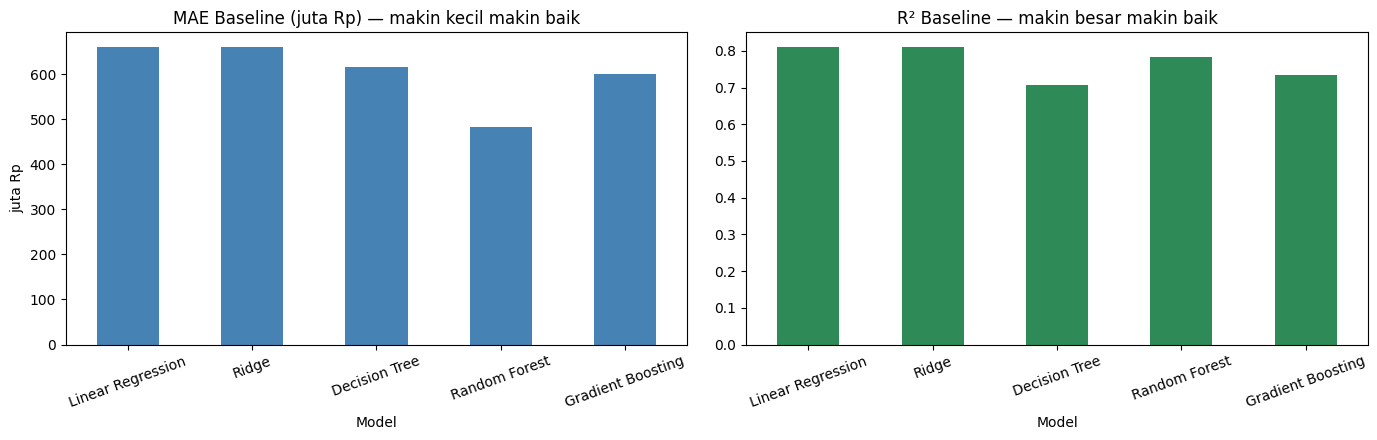

In [ ]:
res_baseline = pd.DataFrame([h for h in hasil_eval if h['Tahap'] == 'Baseline']).set_index('Model').drop(columns='Tahap')
display(res_baseline.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
(res_baseline['MAE (Rp)'] / 1e6).plot(kind='bar', ax=axes[0], color='steelblue', rot=20)
axes[0].set_title('MAE Baseline (juta Rp) — makin kecil makin baik')
axes[0].set_ylabel('juta Rp')
res_baseline['R2'].plot(kind='bar', ax=axes[1], color='seagreen', rot=20)
axes[1].set_title('R² Baseline — makin besar makin baik')
plt.tight_layout()
plt.show()

**Catatan baseline:** model berbasis pohon (Random Forest, Gradient Boosting) biasanya unggul karena tidak peka terhadap skala dan hubungan non-linear harga-luas. Model linear dihambat oleh target yang sangat miring dan encoding `Kecamatan` yang tidak bermakna sebagai angka urut. Part 4 menangani keduanya.

# Part 4 — Preprocessing dan Feature Engineering (Pipeline)

Yang dikerjakan:
1. **Transformasi target** `log1p(Harga)` (distribusi harga terbukti right-skewed).
2. **Feature engineering**: log luas, rasio bangunan/tanah, total kamar, penanda ada garasi.
3. **Encoding `Kecamatan`**: One-Hot (kategori langka digabung otomatis) dibandingkan dengan Target Encoding, dipilih lewat Cross-Validation.
4. Semua dibungkus `ColumnTransformer` + `Pipeline` + `TransformedTargetRegressor`, sehingga imputasi, scaling, dan encoding **hanya belajar dari data train** (di setiap fold Cross-Validation juga).

## 4.1 Bukti perlunya log1p pada target (data train)

Skewness harga train (Rp)    : 5.41
Skewness harga train (log1p) : 0.23


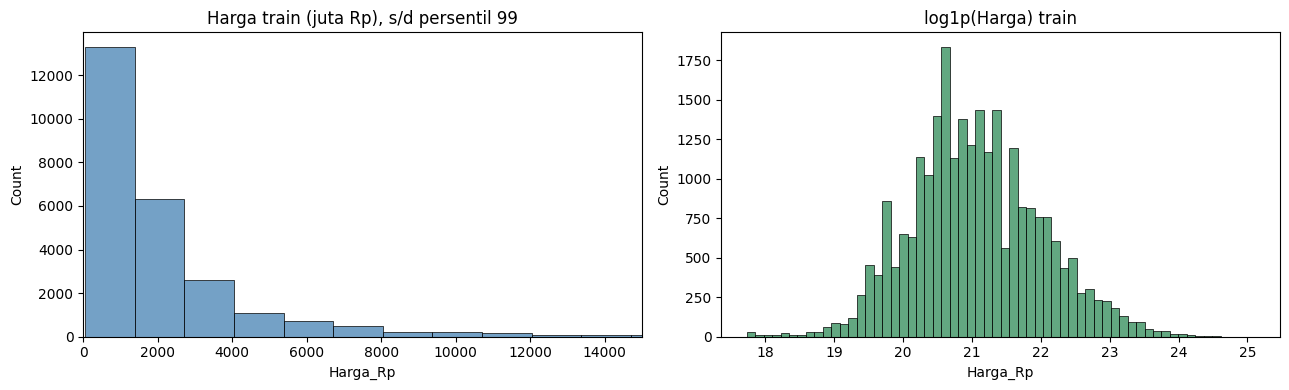

In [ ]:
print("Skewness harga train (Rp)    :", round(y_train.skew(), 2))
print("Skewness harga train (log1p) :", round(np.log1p(y_train).skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y_train / 1e6, bins=60, ax=axes[0], color='steelblue')
axes[0].set_xlim(0, (y_train / 1e6).quantile(0.99))
axes[0].set_title('Harga train (juta Rp), s/d persentil 99')
sns.histplot(np.log1p(y_train), bins=60, ax=axes[1], color='seagreen')
axes[1].set_title('log1p(Harga) train')
plt.tight_layout()
plt.show()

## 4.2 Modul feature engineering (`fitur.py`)
Fungsi ditulis ke file `fitur.py` agar bisa di-import oleh notebook **dan** aplikasi Streamlit (pipeline yang disimpan merujuk ke fungsi ini). Semua operasi aman terhadap nilai kosong (hasilnya NaN, lalu diimputasi di dalam pipeline).

In [ ]:
from pathlib import Path

FITUR_PY = r'''import numpy as np
import pandas as pd

KOLOM_NUMERIK = ["Kamar_Tidur", "Kamar_Mandi", "Garasi", "Luas_Tanah", "Luas_Bangunan"]
FITUR_BARU = ["Log_Luas_Tanah", "Log_Luas_Bangunan", "Rasio_LB_LT", "Total_Kamar", "Ada_Garasi"]
KOLOM_KATEGORI = ["Kecamatan"]
KOLOM_INPUT = KOLOM_NUMERIK + KOLOM_KATEGORI


def rekayasa_fitur(X):
    """Tambahkan fitur turunan. Nilai kosong tetap NaN (diimputasi di dalam pipeline)."""
    X = X.copy()
    lt = X["Luas_Tanah"].astype(float)
    lb = X["Luas_Bangunan"].astype(float)
    X["Log_Luas_Tanah"] = np.log1p(lt)
    X["Log_Luas_Bangunan"] = np.log1p(lb)
    X["Rasio_LB_LT"] = (lb / lt.where(lt > 0)).clip(upper=6)
    X["Total_Kamar"] = X["Kamar_Tidur"].astype(float) + X["Kamar_Mandi"].astype(float)
    X["Ada_Garasi"] = (X["Garasi"].astype(float) > 0).astype(float)
    return X
'''
Path('fitur.py').write_text(FITUR_PY)

import os, importlib
if os.getcwd() not in sys.path:
  sys.path.insert(0, os.getcwd())
import fitur
importlib.reload(fitur)
from fitur import rekayasa_fitur, KOLOM_NUMERIK, FITUR_BARU, KOLOM_KATEGORI

print(rekayasa_fitur(X_train.head(3))[FITUR_BARU])

   Log_Luas_Tanah  Log_Luas_Bangunan  Rasio_LB_LT  Total_Kamar  Ada_Garasi
0            6.08               4.71         0.25         7.00        1.00
1            3.93               4.11         1.20         5.00        1.00
2            3.93               4.11         1.20         5.00        1.00


## 4.3 Pembangun Pipeline

```
TransformedTargetRegressor (log1p / expm1)
 └─ Pipeline
     ├─ rekayasa_fitur            (FunctionTransformer)
     ├─ ColumnTransformer
     │    ├─ numerik   : SimpleImputer(median, +indikator kosong) → StandardScaler
     │    └─ Kecamatan : SimpleImputer(modus) → OneHotEncoder(min_frequency=30) / TargetEncoder
     ├─ (opsional) seleksi fitur   ← dipakai di Part 5
     └─ model
```
`TransformedTargetRegressor` melatih model pada `log1p(Harga)` dan mengembalikan prediksi ke Rupiah dengan `expm1` secara otomatis, sehingga semua metrik tetap di skala Rupiah.

In [ ]:
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, TargetEncoder
from sklearn.compose import TransformedTargetRegressor

KOLOM_PROSES = KOLOM_NUMERIK + FITUR_BARU

def buat_preprocessor(encoding='ohe'):
  if encoding == 'ohe':
    enc_kec = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=False)
  elif encoding == 'target':
    enc_kec = TargetEncoder(target_type='continuous', random_state=SEED)
  else:
    raise ValueError("encoding harus 'ohe' atau 'target'")

  return ColumnTransformer(
      transformers=[
          ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                            ('sc', StandardScaler())]), KOLOM_PROSES),
          ('kec', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                            ('enc', enc_kec)]), KOLOM_KATEGORI),
      ],
      sparse_threshold=0,
  )

def buat_pipeline(model, encoding='ohe', seleksi=None, log_target=True):
  langkah = [('fitur', FunctionTransformer(rekayasa_fitur)),
             ('prep', buat_preprocessor(encoding))]
  if seleksi is not None:
    langkah.append(('seleksi', seleksi))
  langkah.append(('model', model))
  pipe = Pipeline(langkah)
  if log_target:
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
  return pipe

### Uji cepat pipeline (satu model, tanpa error)

In [ ]:
uji = buat_pipeline(Ridge(alpha=1.0))
uji.fit(X_train, y_train)
print("Prediksi 3 baris pertama test (Rp):", uji.predict(X_test.head(3)).round(-5))
print("Harga asli                        :", y_test.head(3).values)

Prediksi 3 baris pertama test (Rp): [7.2180e+08 4.5350e+08 1.9017e+09]
Harga asli                        : [1.20e+09 5.25e+08 2.15e+09]


## 4.4 Pilih encoding `Kecamatan`: One-Hot vs Target Encoding
Dibandingkan dengan Cross-Validation **berbasis grup** pada data train. Metrik dihitung di skala Rupiah. Pemenang ditentukan oleh MAE terendah pada Gradient Boosting.

In [ ]:
cv3 = GroupKFold(n_splits=3)
scoring_rp = {'mae': 'neg_mean_absolute_error',
              'mape': 'neg_mean_absolute_percentage_error',
              'r2': 'r2'}

def cv_ringkas(estimator, nama, n_jobs=-1):
  s = cross_validate(estimator, X_train, y_train, groups=g_train, cv=cv3, scoring=scoring_rp, n_jobs=n_jobs)
  return {'Konfigurasi': nama,
          'CV MAE (Rp)': -s['test_mae'].mean(),
          'CV MAPE (%)': -s['test_mape'].mean() * 100,
          'CV R2': s['test_r2'].mean()}

gb_cv = lambda: GradientBoostingRegressor(n_estimators=150, max_depth=4, random_state=SEED)

baris_enc = [
    cv_ringkas(buat_pipeline(gb_cv(), 'ohe'), 'Gradient Boosting + One-Hot'),
    cv_ringkas(buat_pipeline(gb_cv(), 'target'), 'Gradient Boosting + Target Encoding'),
    cv_ringkas(buat_pipeline(Ridge(alpha=1.0), 'ohe'), 'Ridge + One-Hot'),
    cv_ringkas(buat_pipeline(Ridge(alpha=1.0), 'target'), 'Ridge + Target Encoding'),
]
tabel_enc = pd.DataFrame(baris_enc).set_index('Konfigurasi')
display(tabel_enc.round(3))

gb_rows = tabel_enc.loc[[i for i in tabel_enc.index if i.startswith('Gradient')]]
ENC_TERBAIK = 'ohe' if gb_rows['CV MAE (Rp)'].idxmin().endswith('One-Hot') else 'target'
print("Encoding terpilih untuk Kecamatan:", ENC_TERBAIK)

,CV MAE (Rp),CV MAPE (%),CV R2
Konfigurasi,,,
Gradient Boosting + One-Hot,"561,431,866.76",27.41,0.80
Gradient Boosting + Target Encoding,"558,945,130.61",27.13,0.79
Ridge + One-Hot,"624,987,821.30",30.48,0.69
Ridge + Target Encoding,"630,408,531.19",30.87,0.68


Encoding terpilih untuk Kecamatan: target


## 4.5 Latih 5 model dengan preprocessing lengkap + log1p
Model sama seperti baseline (parameter default) agar selisihnya murni berasal dari preprocessing dan feature engineering.

In [ ]:
model_p4 = {}
for nama, mdl in model_zoo().items():
  pipe = buat_pipeline(mdl, ENC_TERBAIK)
  pipe.fit(X_train, y_train)
  model_p4[nama] = pipe
  evaluasi('Part 4', nama, pipe, X_test, y_test)

[Part 4] Linear Regression      MAE Rp    610.8 jt | MAPE   30.0% | MdAPE  21.0% | R2 0.813
[Part 4] Ridge                  MAE Rp    610.7 jt | MAPE   30.0% | MdAPE  21.0% | R2 0.813
[Part 4] Decision Tree          MAE Rp    592.2 jt | MAPE   29.1% | MdAPE  15.4% | R2 0.733
[Part 4] Random Forest          MAE Rp    465.6 jt | MAPE   22.9% | MdAPE  12.9% | R2 0.759
[Part 4] Gradient Boosting      MAE Rp    585.4 jt | MAPE   26.6% | MdAPE  17.7% | R2 0.693


### Perbandingan Baseline vs Preprocessing (test set)

,MAE baseline (juta),MAE Part 4 (juta),MAPE baseline (%),MAPE Part 4 (%),R2 baseline,R2 Part 4,Selisih MAE (%)
Model,,,,,,,
Linear Regression,659.60,610.75,37.28,30.00,0.81,0.81,-7.41
Ridge,659.60,610.74,37.28,30.00,0.81,0.81,-7.41
Decision Tree,616.05,592.23,30.23,29.14,0.71,0.73,-3.87
Random Forest,482.83,465.64,25.16,22.91,0.78,0.76,-3.56
Gradient Boosting,599.49,585.40,32.71,26.61,0.73,0.69,-2.35


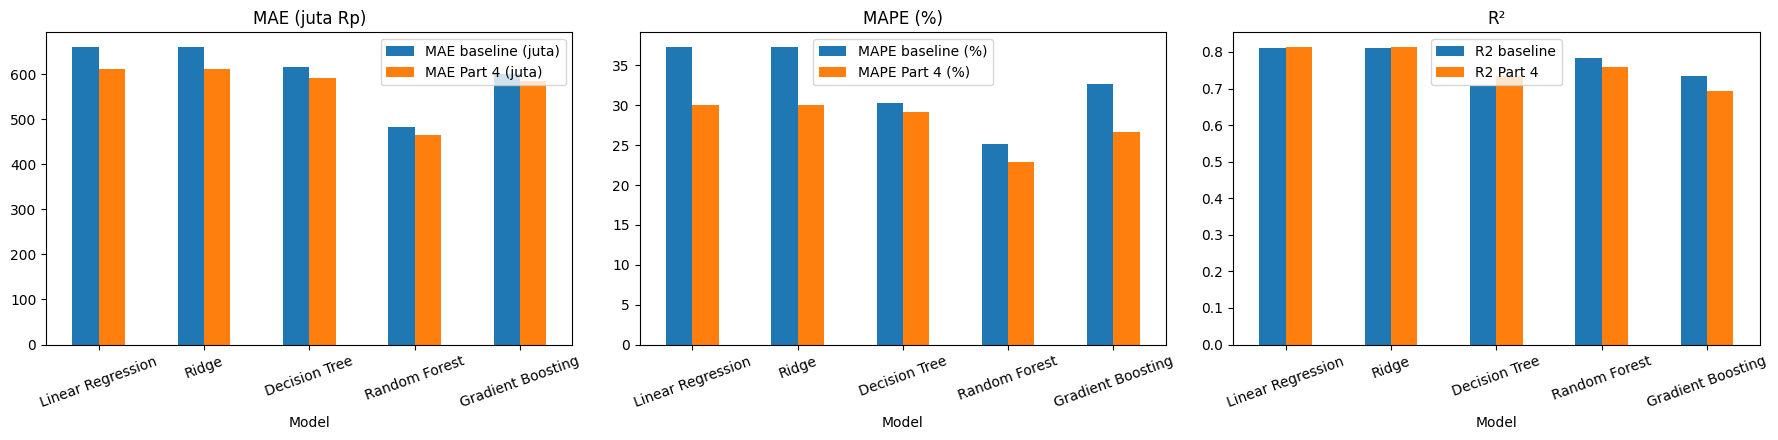

In [ ]:
res_p4 = pd.DataFrame([h for h in hasil_eval if h['Tahap'] == 'Part 4']).set_index('Model').drop(columns='Tahap')

banding = pd.DataFrame({
    'MAE baseline (juta)': res_baseline['MAE (Rp)'] / 1e6,
    'MAE Part 4 (juta)': res_p4['MAE (Rp)'] / 1e6,
    'MAPE baseline (%)': res_baseline['MAPE (%)'],
    'MAPE Part 4 (%)': res_p4['MAPE (%)'],
    'R2 baseline': res_baseline['R2'],
    'R2 Part 4': res_p4['R2'],
})
banding['Selisih MAE (%)'] = (banding['MAE Part 4 (juta)'] / banding['MAE baseline (juta)'] - 1) * 100
display(banding.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (a, b, judul) in zip(axes, [('MAE baseline (juta)', 'MAE Part 4 (juta)', 'MAE (juta Rp)'),
                                    ('MAPE baseline (%)', 'MAPE Part 4 (%)', 'MAPE (%)'),
                                    ('R2 baseline', 'R2 Part 4', 'R²')]):
  banding[[a, b]].plot(kind='bar', ax=ax, rot=20)
  ax.set_title(judul)
plt.tight_layout()
plt.show()

# Part 5 — Feature Selection dan Hyperparameter Tuning

Urutan kerja (semua keputusan memakai **data train** saja):
1. Feature importance (impurity + permutation) dan korelasi.
2. Seleksi fitur di dalam pipeline, dipilih lewat Cross-Validation.
3. Hyperparameter tuning (`GridSearchCV` / `RandomizedSearchCV`) dengan `GroupKFold`.
4. Model akhir dipilih dari **skor Cross-Validation**, lalu dilaporkan pada test set (prediksi dikembalikan ke Rupiah dengan `expm1`).

## 5.1 Feature Importance dan Korelasi
Importance dihitung pada sebagian data train (`X_a`) dan permutation importance diukur pada sisa data train (`X_b`). Test set tidak disentuh.

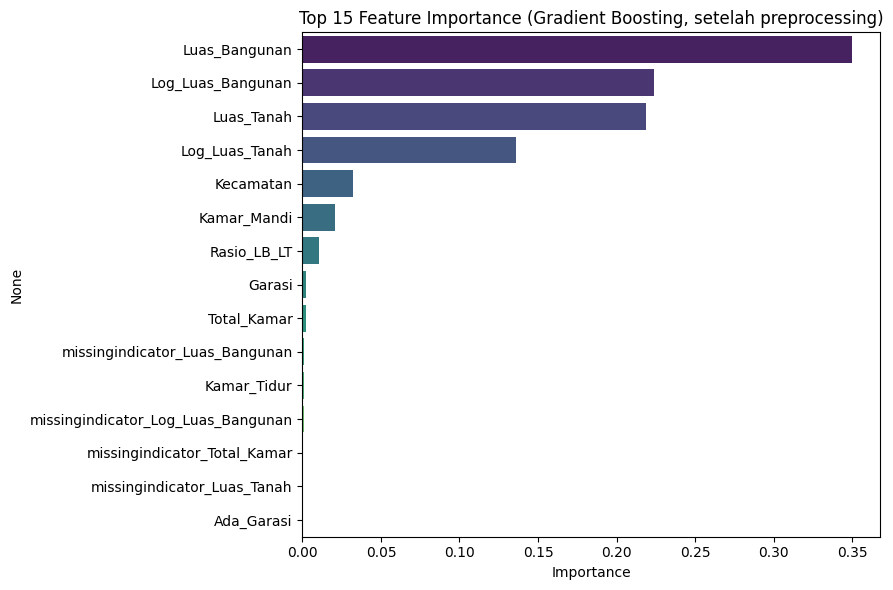

In [ ]:
from sklearn.inspection import permutation_importance

idx_a, idx_b = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(X_train, y_train, groups=g_train))
X_a, X_b = X_train.iloc[idx_a], X_train.iloc[idx_b]
y_a, y_b = y_train.iloc[idx_a], y_train.iloc[idx_b]

pipe_imp = buat_pipeline(GradientBoostingRegressor(n_estimators=200, max_depth=4, random_state=SEED), ENC_TERBAIK)
pipe_imp.fit(X_a, y_a)

nama_fitur = [n.split('__', 1)[1] for n in pipe_imp.regressor_.named_steps['prep'].get_feature_names_out()]
imp_impurity = pd.Series(pipe_imp.regressor_.named_steps['model'].feature_importances_, index=nama_fitur).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=imp_impurity.values[:15], y=imp_impurity.index[:15], palette='viridis', ax=ax)
ax.set_title('Top 15 Feature Importance (Gradient Boosting, setelah preprocessing)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

### Permutation importance (fitur input asli)
Seberapa besar MAE memburuk bila satu kolom input diacak (di data validasi `X_b`).

,Fitur,Kenaikan MAE (juta Rp),Std
3,Luas_Tanah,701.33,15.25
4,Luas_Bangunan,377.58,9.54
5,Kecamatan,133.52,2.96
1,Kamar_Mandi,56.50,2.61
0,Kamar_Tidur,16.75,1.27
2,Garasi,5.79,1.12


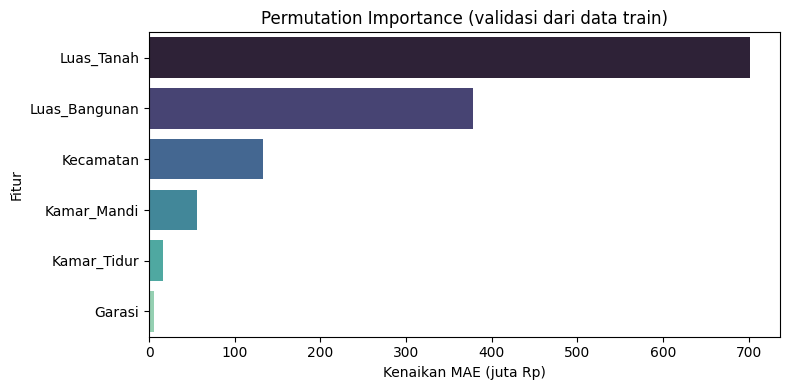

In [ ]:
perm = permutation_importance(pipe_imp, X_b, y_b, scoring='neg_mean_absolute_error',
                              n_repeats=5, random_state=SEED, n_jobs=1)
perm_df = pd.DataFrame({'Fitur': X_b.columns, 'Kenaikan MAE (juta Rp)': perm.importances_mean / 1e6,
                        'Std': perm.importances_std / 1e6}).sort_values('Kenaikan MAE (juta Rp)', ascending=False)
display(perm_df.round(2))

plt.figure(figsize=(8, 4))
sns.barplot(data=perm_df, x='Kenaikan MAE (juta Rp)', y='Fitur', palette='mako')
plt.title('Permutation Importance (validasi dari data train)')
plt.tight_layout()
plt.show()

### Korelasi fitur dengan log harga (Spearman, data train)

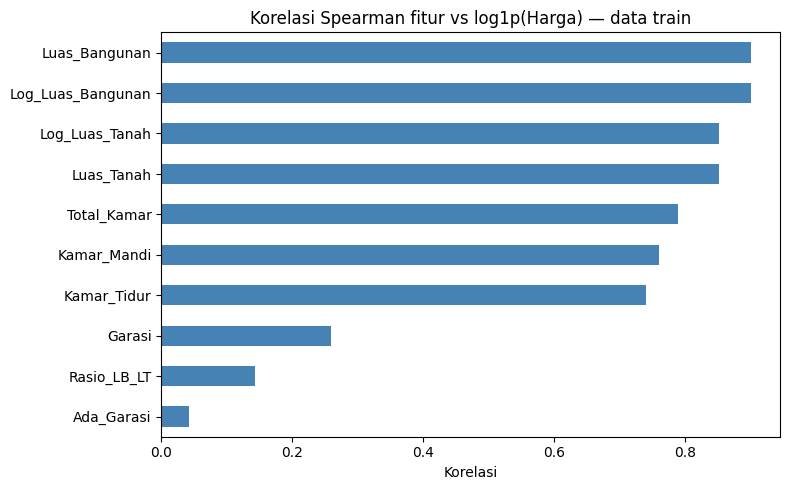

In [ ]:
fe_train = rekayasa_fitur(X_train)[KOLOM_PROSES]
kor = fe_train.corrwith(np.log1p(y_train), method='spearman').sort_values()

plt.figure(figsize=(8, 5))
kor.plot(kind='barh', color='steelblue')
plt.title('Korelasi Spearman fitur vs log1p(Harga) — data train')
plt.xlabel('Korelasi')
plt.tight_layout()
plt.show()

## 5.2 Seleksi Fitur di dalam Pipeline
`SelectFromModel` (berbasis Random Forest) berada **di dalam pipeline**, jadi dihitung ulang pada tiap fold dan tidak membocorkan data validasi. Tiga opsi dibandingkan dengan Cross-Validation; yang MAE-nya terendah dipakai.

In [ ]:
from sklearn.feature_selection import SelectFromModel

def buat_seleksi(threshold):
  return SelectFromModel(
      RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5, n_jobs=1, random_state=SEED),
      threshold=threshold)

opsi_seleksi = {'Tanpa seleksi': None, 'SelectFromModel (0.5*mean)': '0.5*mean', 'SelectFromModel (mean)': 'mean'}

baris_sel = []
for nama, th in opsi_seleksi.items():
  sel = buat_seleksi(th) if th is not None else None
  baris_sel.append(cv_ringkas(buat_pipeline(gb_cv(), ENC_TERBAIK, seleksi=sel), nama))

tabel_sel = pd.DataFrame(baris_sel).set_index('Konfigurasi')
display(tabel_sel.round(3))

nama_terbaik = tabel_sel['CV MAE (Rp)'].idxmin()
TH_TERBAIK = opsi_seleksi[nama_terbaik]
print("Seleksi fitur terpilih:", nama_terbaik)

def seleksi_final():
  return buat_seleksi(TH_TERBAIK) if TH_TERBAIK is not None else None

,CV MAE (Rp),CV MAPE (%),CV R2
Konfigurasi,,,
Tanpa seleksi,"558,945,130.61",27.13,0.79
SelectFromModel (0.5*mean),"568,356,285.75",28.57,0.79
SelectFromModel (mean),"615,522,226.89",31.43,0.77


Seleksi fitur terpilih: Tanpa seleksi


### Fitur yang dipertahankan

In [ ]:
if TH_TERBAIK is not None:
  pipe_sel = buat_pipeline(gb_cv(), ENC_TERBAIK, seleksi=seleksi_final())
  pipe_sel.fit(X_train, y_train)
  nama_all = [n.split('__', 1)[1] for n in pipe_sel.regressor_.named_steps['prep'].get_feature_names_out()]
  mask = pipe_sel.regressor_.named_steps['seleksi'].get_support()
  print(f"Fitur dipertahankan: {mask.sum()} dari {len(mask)}")
  print("Dibuang:", [n for n, k in zip(nama_all, mask) if not k])
else:
  print("Semua fitur dipertahankan (seleksi tidak memperbaiki CV).")

Semua fitur dipertahankan (seleksi tidak memperbaiki CV).


## 5.3 Hyperparameter Tuning

- `Linear Regression`: tanpa hyperparameter (dievaluasi dengan Cross-Validation yang sama sebagai pembanding).
- `Ridge`, `Decision Tree`: `GridSearchCV`.
- `Random Forest`, `Gradient Boosting`: `RandomizedSearchCV`.
- Cross-Validation: `GroupKFold(3)` pada data train. Skor dihitung di skala Rupiah; model dipilih (`refit`) berdasarkan **MAE**.
- Ukuran ruang pencarian Random Forest sengaja dibatasi (`min_samples_leaf` ≥ 3, `max_depth` ≤ 20) agar file model tetap kecil untuk deployment.

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

N_ITER_RF = 3 if QUICK else 8
N_ITER_GB = 4 if QUICK else 12

cv_tuning = GroupKFold(n_splits=3)
scoring_multi = {'mae': 'neg_mean_absolute_error',
                 'mape': 'neg_mean_absolute_percentage_error',
                 'r2': 'r2'}

hasil_tuning = {}

def catat_pencarian(nama, search):
  i = search.best_index_
  r = search.cv_results_
  hasil_tuning[nama] = {
      'estimator': search.best_estimator_,
      'params': {k.replace('regressor__model__', ''): v for k, v in search.best_params_.items()},
      'cv_mae': -r['mean_test_mae'][i],
      'cv_mape': -r['mean_test_mape'][i] * 100,
      'cv_r2': r['mean_test_r2'][i],
  }
  print(f"{nama}: CV MAE Rp{hasil_tuning[nama]['cv_mae']/1e6:,.1f} jt | parameter terbaik: {hasil_tuning[nama]['params']}")
  evaluasi('Tuned', nama, search.best_estimator_, X_test, y_test)

### Linear Regression (tanpa tuning)

In [ ]:
lr_pipe = buat_pipeline(LinearRegression(), ENC_TERBAIK, seleksi=seleksi_final())
r = cv_ringkas(lr_pipe, 'Linear Regression')
lr_pipe.fit(X_train, y_train)
hasil_tuning['Linear Regression'] = {'estimator': lr_pipe, 'params': {},
                                     'cv_mae': r['CV MAE (Rp)'], 'cv_mape': r['CV MAPE (%)'], 'cv_r2': r['CV R2']}
evaluasi('Tuned', 'Linear Regression', lr_pipe, X_test, y_test)

[Tuned] Linear Regression      MAE Rp    610.8 jt | MAPE   30.0% | MdAPE  21.0% | R2 0.813


array([7.38606085e+08, 4.07568803e+08, 1.90095349e+09, ...,
       3.87692053e+08, 1.08936777e+09, 5.08833876e+08])

### Ridge (GridSearchCV)

In [ ]:
gs_ridge = GridSearchCV(
    buat_pipeline(Ridge(random_state=SEED), ENC_TERBAIK, seleksi=seleksi_final()),
    param_grid={'regressor__model__alpha': [0.01, 0.1, 1, 3, 10, 30, 100]},
    scoring=scoring_multi, refit='mae', cv=cv_tuning, n_jobs=-1)
gs_ridge.fit(X_train, y_train, groups=g_train)
catat_pencarian('Ridge', gs_ridge)

Ridge: CV MAE Rp628.9 jt | parameter terbaik: {'alpha': 100}
[Tuned] Ridge                  MAE Rp    609.3 jt | MAPE   30.0% | MdAPE  21.1% | R2 0.816


### Decision Tree (GridSearchCV)

In [ ]:
gs_dt = GridSearchCV(
    buat_pipeline(DecisionTreeRegressor(random_state=SEED), ENC_TERBAIK, seleksi=seleksi_final()),
    param_grid={'regressor__model__max_depth': [6, 8, 10, 14, None],
                'regressor__model__min_samples_leaf': [1, 5, 10, 20]},
    scoring=scoring_multi, refit='mae', cv=cv_tuning, n_jobs=-1)
gs_dt.fit(X_train, y_train, groups=g_train)
catat_pencarian('Decision Tree', gs_dt)

Decision Tree: CV MAE Rp578.7 jt | parameter terbaik: {'max_depth': None, 'min_samples_leaf': 10}
[Tuned] Decision Tree          MAE Rp    544.0 jt | MAPE   26.5% | MdAPE  15.9% | R2 0.791


### Random Forest (RandomizedSearchCV)

In [ ]:
rs_rf = RandomizedSearchCV(
    buat_pipeline(RandomForestRegressor(n_jobs=1, random_state=SEED), ENC_TERBAIK, seleksi=seleksi_final()),
    param_distributions={
        'regressor__model__n_estimators': [100, 150, 200],
        'regressor__model__max_depth': [12, 16, 20],
        'regressor__model__min_samples_leaf': [3, 5, 8],
        'regressor__model__min_samples_split': [2, 5],
        'regressor__model__max_features': [0.5, 0.8, 1.0],
    },
    n_iter=N_ITER_RF, scoring=scoring_multi, refit='mae', cv=cv_tuning, n_jobs=-1, random_state=SEED)
rs_rf.fit(X_train, y_train, groups=g_train)
catat_pencarian('Random Forest', rs_rf)

Random Forest: CV MAE Rp493.2 jt | parameter terbaik: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 3, 'max_features': 0.8, 'max_depth': 20}
[Tuned] Random Forest          MAE Rp    473.6 jt | MAPE   23.1% | MdAPE  13.5% | R2 0.783


### Gradient Boosting (RandomizedSearchCV)

In [ ]:
rs_gb = RandomizedSearchCV(
    buat_pipeline(GradientBoostingRegressor(random_state=SEED), ENC_TERBAIK, seleksi=seleksi_final()),
    param_distributions={
        'regressor__model__n_estimators': [200, 300, 400],
        'regressor__model__learning_rate': [0.03, 0.05, 0.1],
        'regressor__model__max_depth': [3, 4, 5],
        'regressor__model__subsample': [0.7, 0.85, 1.0],
        'regressor__model__min_samples_leaf': [1, 5, 10],
    },
    n_iter=N_ITER_GB, scoring=scoring_multi, refit='mae', cv=cv_tuning, n_jobs=-1, random_state=SEED)
rs_gb.fit(X_train, y_train, groups=g_train)
catat_pencarian('Gradient Boosting', rs_gb)

Gradient Boosting: CV MAE Rp518.4 jt | parameter terbaik: {'subsample': 0.85, 'n_estimators': 400, 'min_samples_leaf': 5, 'max_depth': 5, 'learning_rate': 0.1}
[Tuned] Gradient Boosting      MAE Rp    521.0 jt | MAPE   24.5% | MdAPE  15.8% | R2 0.748


## 5.4 Perbandingan Seluruh Tahap (test set)

MAE (juta Rp):


Tahap,Baseline,Part 4,Tuned
Model,,,
Decision Tree,616.10,592.20,544.00
Gradient Boosting,599.50,585.40,521.00
Linear Regression,659.60,610.80,610.80
Random Forest,482.80,465.60,473.60
Ridge,659.60,610.70,609.30


MAPE (%):


Tahap,Baseline,Part 4,Tuned
Model,,,
Decision Tree,30.20,29.10,26.50
Gradient Boosting,32.70,26.60,24.50
Linear Regression,37.30,30.00,30.00
Random Forest,25.20,22.90,23.10
Ridge,37.30,30.00,30.00


R²:


Tahap,Baseline,Part 4,Tuned
Model,,,
Decision Tree,0.71,0.73,0.79
Gradient Boosting,0.73,0.69,0.75
Linear Regression,0.81,0.81,0.81
Random Forest,0.78,0.76,0.78
Ridge,0.81,0.81,0.82


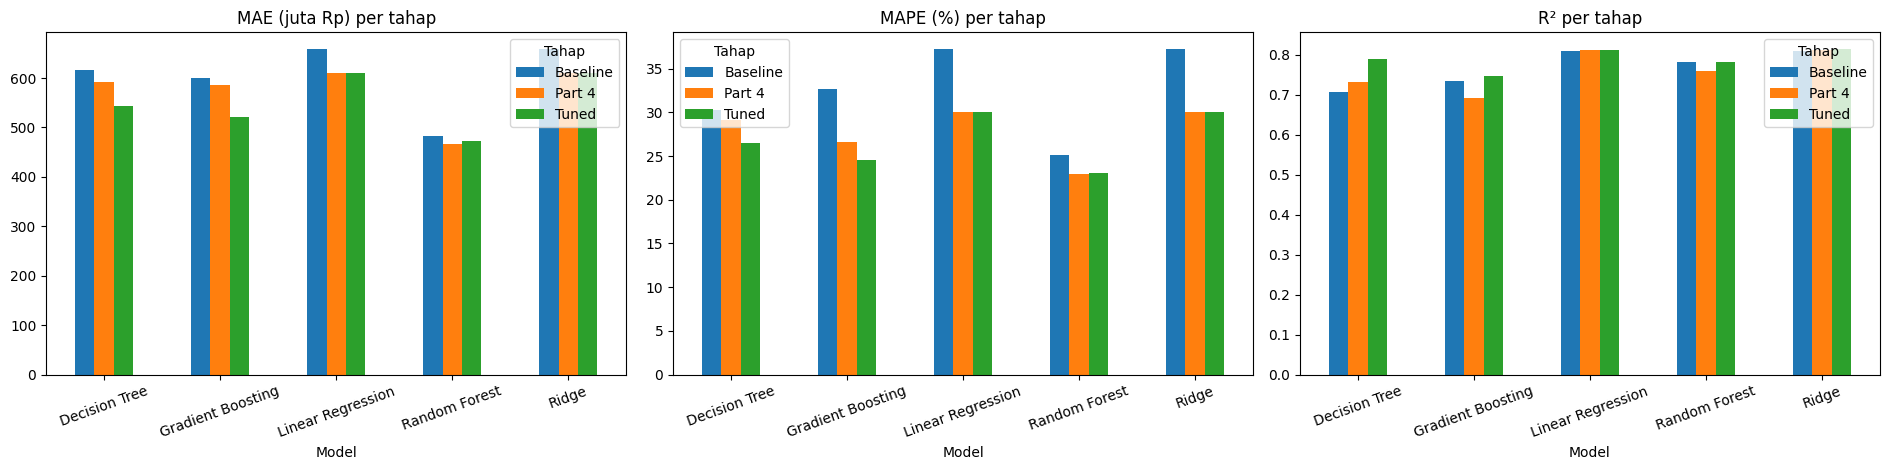

In [ ]:
semua = pd.DataFrame(hasil_eval)
urutan_tahap = ['Baseline', 'Part 4', 'Tuned']

tabel_mae = semua.pivot(index='Model', columns='Tahap', values='MAE (Rp)')[urutan_tahap] / 1e6
tabel_mape = semua.pivot(index='Model', columns='Tahap', values='MAPE (%)')[urutan_tahap]
tabel_r2 = semua.pivot(index='Model', columns='Tahap', values='R2')[urutan_tahap]

print("MAE (juta Rp):"); display(tabel_mae.round(1))
print("MAPE (%):"); display(tabel_mape.round(1))
print("R²:"); display(tabel_r2.round(3))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, tb, judul in zip(axes, [tabel_mae, tabel_mape, tabel_r2], ['MAE (juta Rp)', 'MAPE (%)', 'R²']):
  tb.plot(kind='bar', ax=ax, rot=20)
  ax.set_title(judul + ' per tahap')
plt.tight_layout()
plt.show()

## 5.5 Pemilihan Model Akhir dan Evaluasi pada Test Set
Pemilih = **MAE Cross-Validation terendah** (bukan skor test). Test set hanya melaporkan.

In [ ]:
cv_tabel = pd.DataFrame({n: {'CV MAE (juta Rp)': v['cv_mae'] / 1e6, 'CV MAPE (%)': v['cv_mape'], 'CV R2': v['cv_r2']}
                         for n, v in hasil_tuning.items()}).T.sort_values('CV MAE (juta Rp)')
display(cv_tabel.round(3))

nama_final = cv_tabel.index[0]
model_final = hasil_tuning[nama_final]['estimator']
print("Model akhir terpilih (CV MAE terendah):", nama_final)
print("Parameter:", hasil_tuning[nama_final]['params'])

,CV MAE (juta Rp),CV MAPE (%),CV R2
Random Forest,493.21,24.91,0.81
Gradient Boosting,518.41,25.74,0.82
Decision Tree,578.72,28.73,0.76
Ridge,628.87,30.88,0.68
Linear Regression,630.45,30.87,0.68


Model akhir terpilih (CV MAE terendah): Random Forest
Parameter: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 3, 'max_features': 0.8, 'max_depth': 20}


### Prediksi log1p dikembalikan ke Rupiah dengan `expm1`

In [ ]:
pred_log = model_final.regressor_.predict(X_test)     # skala log1p(Harga)
pred_rp = np.expm1(pred_log)                          # kembali ke Rupiah
assert np.allclose(pred_rp, model_final.predict(X_test))

metrik_final = hitung_metrik(y_test, pred_rp)
print("Contoh 5 prediksi (log1p)  :", pred_log[:5].round(3))
print("Contoh 5 prediksi (Rupiah) :", pred_rp[:5].round(-5))
print()
print(f"MAE   : Rp{metrik_final['MAE (Rp)']:,.0f}")
print(f"MAPE  : {metrik_final['MAPE (%)']:.2f}%")
print(f"MdAPE : {metrik_final['MdAPE (%)']:.2f}%")
print(f"R²    : {metrik_final['R2']:.4f}")
print(f"\nPerbandingan CV vs test (MAE): CV Rp{hasil_tuning[nama_final]['cv_mae']/1e6:,.1f} jt vs test Rp{metrik_final['MAE (Rp)']/1e6:,.1f} jt")

Contoh 5 prediksi (log1p)  : [20.675 20.077 21.488 21.631 20.207]
Contoh 5 prediksi (Rupiah) : [9.5270e+08 5.2390e+08 2.1489e+09 2.4797e+09 5.9690e+08]

MAE   : Rp473,607,510
MAPE  : 23.09%
MdAPE : 13.47%
R²    : 0.7828

Perbandingan CV vs test (MAE): CV Rp493.2 jt vs test Rp473.6 jt


### Prediksi vs harga sebenarnya

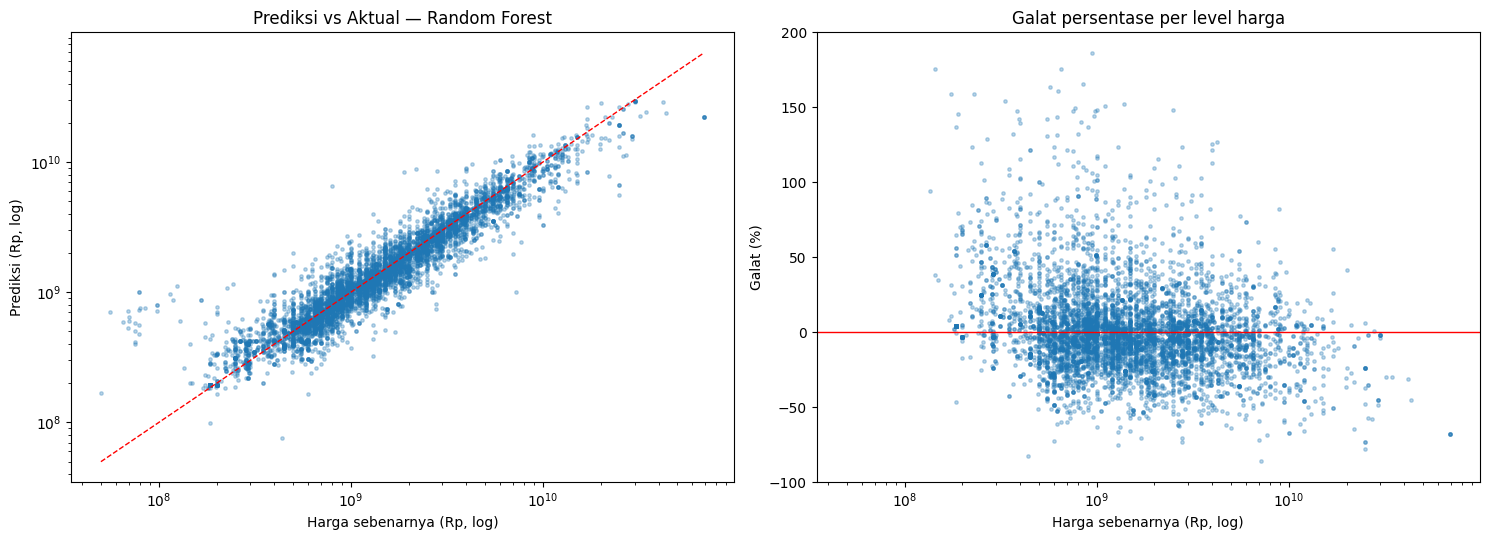

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(y_test, pred_rp, s=6, alpha=0.3)
lim = [min(y_test.min(), pred_rp.min()), max(y_test.max(), pred_rp.max())]
axes[0].plot(lim, lim, 'r--', lw=1)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Harga sebenarnya (Rp, log)'); axes[0].set_ylabel('Prediksi (Rp, log)')
axes[0].set_title(f'Prediksi vs Aktual — {nama_final}')

galat_pct = (pred_rp - y_test.values) / y_test.values * 100
axes[1].scatter(y_test, galat_pct, s=6, alpha=0.3)
axes[1].axhline(0, color='r', lw=1)
axes[1].set_xscale('log'); axes[1].set_ylim(-100, 200)
axes[1].set_xlabel('Harga sebenarnya (Rp, log)'); axes[1].set_ylabel('Galat (%)')
axes[1].set_title('Galat persentase per level harga')
plt.tight_layout()
plt.show()

### Galat per segmen harga

In [ ]:
segmen = pd.cut(y_test, bins=[0, 5e8, 1e9, 2e9, 5e9, np.inf],
                labels=['< 500 jt', '500 jt - 1 M', '1 - 2 M', '2 - 5 M', '> 5 M'])
ape_seg = pd.DataFrame({'segmen': segmen.values, 'APE': np.abs(pred_rp - y_test.values) / y_test.values * 100,
                        'AE': np.abs(pred_rp - y_test.values)})
tabel_seg = ape_seg.groupby('segmen', observed=True).agg(Jumlah=('APE', 'size'), MAPE=('APE', 'mean'),
                                                         MdAPE=('APE', 'median'), MAE_juta=('AE', lambda s: s.mean() / 1e6))
display(tabel_seg.round(1))

,Jumlah,MAPE,MdAPE,MAE_juta
segmen,,,,
< 500 jt,856,49.70,15.60,112.50
500 jt - 1 M,1887,20.40,13.00,157.10
1 - 2 M,1693,18.10,12.70,271.90
2 - 5 M,1446,17.90,12.80,569.80
> 5 M,596,20.20,15.60,"2,334.00"


# Part 6 — Deployment Streamlit

Langkah:
1. Pilih model yang muat dibagikan lewat GitHub (file model < 90 MB, batas GitHub 100 MB).
2. Simpan pipeline lengkap (feature engineering + preprocessing + model + `expm1`) ke `.joblib`.
3. Tulis `app.py`, `requirements.txt`, dan metadata.
4. Uji pemuatan model seperti yang dilakukan aplikasi.
5. Publikasi ke GitHub dan Streamlit Cloud (panduan di akhir).

## 6.1 Pilih model deployment dan simpan `.joblib`
Kandidat diurutkan menurut MAE Cross-Validation. Model pertama yang ukuran file terkompresnya ≤ 90 MB dipakai. (Random Forest besar bisa melebihi batas; Gradient Boosting/Ridge/Decision Tree kecil.)

In [ ]:
import os, json, shutil
import joblib
import sklearn

FOLDER = Path('deploy_streamlit')
FOLDER.mkdir(exist_ok=True)
BATAS_MB = 90

peringkat = sorted(hasil_tuning.items(), key=lambda kv: kv[1]['cv_mae'])
nama_deploy, model_deploy = None, None
for nama, info in peringkat:
  tmp = FOLDER / 'tmp_model.joblib'
  joblib.dump(info['estimator'], tmp, compress=3)
  ukuran = os.path.getsize(tmp) / 1e6
  print(f"{nama:<20} CV MAE Rp{info['cv_mae']/1e6:>8,.1f} jt | ukuran file {ukuran:6.1f} MB")
  if ukuran <= BATAS_MB:
    nama_deploy, model_deploy = nama, info['estimator']
    tmp.replace(FOLDER / 'model_harga_rumah.joblib')
    break
  tmp.unlink()

assert model_deploy is not None, "Tidak ada model yang muat di bawah batas ukuran"
print(f"\nModel deployment: {nama_deploy}")
if nama_deploy != nama_final:
  print(f"(Catatan: model akhir terbaik {nama_final} terlalu besar, jadi dipakai {nama_deploy})")

Random Forest        CV MAE Rp   493.2 jt | ukuran file   36.0 MB

Model deployment: Random Forest


### Metadata untuk aplikasi (daftar Kecamatan, rentang input, akurasi test)

In [ ]:
pred_dep = model_deploy.predict(X_test)
m_dep = hitung_metrik(y_test, pred_dep)

meta = {
    'model': nama_deploy,
    'sklearn_version': sklearn.__version__,
    'kecamatan': sorted(X_train['Kecamatan'].unique().tolist()),
    'rentang': {
        'kamar_tidur': [1, BATAS['kamar_maks']],
        'kamar_mandi': [1, BATAS['kamar_maks']],
        'garasi': [0, BATAS['garasi_maks']],
        'luas_tanah': list(BATAS['lt_rentang']),
        'luas_bangunan': list(BATAS['lb_rentang']),
    },
    'default': {
        'kamar_tidur': int(X_train['Kamar_Tidur'].median()),
        'kamar_mandi': int(X_train['Kamar_Mandi'].median()),
        'garasi': int(X_train['Garasi'].median()),
        'luas_tanah': int(X_train['Luas_Tanah'].median()),
        'luas_bangunan': int(X_train['Luas_Bangunan'].median()),
    },
    'metrik_test': {k: float(v) for k, v in m_dep.items()},
    'jumlah_data_latih': int(len(X_train)),
}
(FOLDER / 'meta_model.json').write_text(json.dumps(meta, indent=2, ensure_ascii=False))
shutil.copy('fitur.py', FOLDER / 'fitur.py')
print(json.dumps({k: meta[k] for k in ('model', 'sklearn_version', 'metrik_test')}, indent=2))

{
  "model": "Random Forest",
  "sklearn_version": "1.6.1",
  "metrik_test": {
    "MAE (Rp)": 473607510.05845994,
    "MAPE (%)": 23.090195656222008,
    "MdAPE (%)": 13.470117018553518,
    "R2": 0.7828425310756452
  }
}


## 6.2 Aplikasi Streamlit (`app.py`)
Form input: kamar tidur, kamar mandi, garasi, luas tanah, luas bangunan, Kecamatan. Luas bangunan boleh dikosongkan (model mengimputasi dari data latih). Hasil: harga prediksi dalam Rupiah dan rentang perkiraan berdasarkan MdAPE test.

In [ ]:
APP_PY = r'''import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import streamlit as st

import fitur  # noqa: F401  (pipeline yang disimpan merujuk ke fitur.rekayasa_fitur)

BASE = Path(__file__).parent

st.set_page_config(page_title="Prediksi Harga Rumah", page_icon="🏠", layout="centered")


@st.cache_resource
def muat_model():
    return joblib.load(BASE / "model_harga_rumah.joblib")


@st.cache_data
def muat_meta():
    return json.loads((BASE / "meta_model.json").read_text(encoding="utf-8"))


def format_rupiah(x):
    if x >= 1e9:
        return f"Rp {x / 1e9:,.2f} Miliar".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"Rp {x / 1e6:,.0f} Juta".replace(",", ".")


model = muat_model()
meta = muat_meta()
r, d = meta["rentang"], meta["default"]

st.title("🏠 Prediksi Harga Rumah")
st.caption("Estimasi harga rumah tapak berdasarkan data listing. Hasil adalah perkiraan, bukan penilaian resmi.")

with st.form("form_rumah"):
    kecamatan = st.selectbox("Kecamatan / area", meta["kecamatan"], index=meta["kecamatan"].index("Cinere") if "Cinere" in meta["kecamatan"] else 0)

    c1, c2, c3 = st.columns(3)
    kt = c1.number_input("Kamar tidur", r["kamar_tidur"][0], r["kamar_tidur"][1], d["kamar_tidur"], step=1)
    km = c2.number_input("Kamar mandi", r["kamar_mandi"][0], r["kamar_mandi"][1], d["kamar_mandi"], step=1)
    garasi = c3.number_input("Garasi (mobil)", r["garasi"][0], r["garasi"][1], d["garasi"], step=1)

    c4, c5 = st.columns(2)
    lt = c4.number_input("Luas tanah (m²)", r["luas_tanah"][0], r["luas_tanah"][1], d["luas_tanah"], step=5)
    lb = c5.number_input("Luas bangunan (m²)", r["luas_bangunan"][0], r["luas_bangunan"][1], d["luas_bangunan"], step=5)
    lb_tidak_tahu = st.checkbox("Luas bangunan tidak diketahui")

    kirim = st.form_submit_button("Prediksi harga", type="primary")

if kirim:
    data = pd.DataFrame([{
        "Kamar_Tidur": float(kt),
        "Kamar_Mandi": float(km),
        "Garasi": float(garasi),
        "Luas_Tanah": float(lt),
        "Luas_Bangunan": np.nan if lb_tidak_tahu else float(lb),
        "Kecamatan": kecamatan,
    }])
    harga = float(model.predict(data)[0])
    mdape = meta["metrik_test"]["MdAPE (%)"] / 100

    st.subheader(format_rupiah(harga))
    st.write(f"Perkiraan rentang: **{format_rupiah(harga * (1 - mdape))}** sampai **{format_rupiah(harga * (1 + mdape))}**")
    st.caption(f"Rentang memakai median galat pada data uji (±{mdape * 100:.0f}%). Galat bisa lebih besar untuk rumah mewah atau data yang tidak biasa.")

    if not lb_tidak_tahu and lb > lt * 6:
        st.warning("Luas bangunan tampak tidak wajar dibanding luas tanah. Periksa kembali input.")

with st.expander("Tentang model"):
    m = meta["metrik_test"]
    st.write(f"Model: **{meta['model']}** (dilatih pada {meta['jumlah_data_latih']:,} listing).")
    st.write(f"Evaluasi test set: MAE Rp {m['MAE (Rp)'] / 1e6:,.0f} juta, MAPE {m['MAPE (%)']:.1f}%, MdAPE {m['MdAPE (%)']:.1f}%, R² {m['R2']:.2f}.")
    st.write("Data: hasil scraping listing rumah. Harga listing adalah harga penawaran, bukan harga transaksi.")
'''
(FOLDER / 'app.py').write_text(APP_PY, encoding='utf-8')

REQ = f"""streamlit>=1.32
pandas>=2.0
numpy>=1.24
scikit-learn=={sklearn.__version__}
joblib>=1.3
"""
(FOLDER / 'requirements.txt').write_text(REQ)

print("File di folder deploy_streamlit/:")
for f in sorted(FOLDER.iterdir()):
  print(f"  {f.name:<24} {os.path.getsize(f)/1e6:8.3f} MB")

File di folder deploy_streamlit/:
  app.py                      0.003 MB
  fitur.py                    0.001 MB
  meta_model.json             0.001 MB
  model_harga_rumah.joblib   35.953 MB
  requirements.txt            0.000 MB


## 6.3 Uji pemuatan model seperti di aplikasi
Memuat `.joblib` dari folder deployment di proses terpisah-secara-logis (dari file, bukan objek di memori) dan memprediksi satu input contoh, termasuk kasus luas bangunan kosong.

In [ ]:
import ast
ast.parse((FOLDER / 'app.py').read_text(encoding='utf-8'))   # sintaks app.py valid
print("Sintaks app.py valid")

model_uji = joblib.load(FOLDER / 'model_harga_rumah.joblib')
meta_uji = json.loads((FOLDER / 'meta_model.json').read_text(encoding='utf-8'))

contoh = pd.DataFrame([
    {'Kamar_Tidur': 3.0, 'Kamar_Mandi': 2.0, 'Garasi': 1.0, 'Luas_Tanah': 90.0, 'Luas_Bangunan': 70.0, 'Kecamatan': meta_uji['kecamatan'][0]},
    {'Kamar_Tidur': 4.0, 'Kamar_Mandi': 3.0, 'Garasi': 2.0, 'Luas_Tanah': 200.0, 'Luas_Bangunan': np.nan, 'Kecamatan': 'Cinere'},
])
harga_uji = model_uji.predict(contoh)
for (_, baris), h in zip(contoh.iterrows(), harga_uji):
  print(f"{baris['Kecamatan']:<14} KT {baris['Kamar_Tidur']:.0f} KM {baris['Kamar_Mandi']:.0f} LT {baris['Luas_Tanah']:.0f} LB {baris['Luas_Bangunan']} -> Rp{h:,.0f}")

# prediksi dari file harus sama dengan model di memori
assert np.allclose(model_uji.predict(X_test.head(50)), model_deploy.predict(X_test.head(50)))
print("Prediksi dari file .joblib identik dengan model di memori")

Sintaks app.py valid
Babadan        KT 3 KM 2 LT 90 LB 70.0 -> Rp894,098,572
Cinere         KT 4 KM 3 LT 200 LB nan -> Rp1,634,277,530
Prediksi dari file .joblib identik dengan model di memori


## 6.4 Unduh folder deployment (Colab)

In [ ]:
shutil.make_archive('deploy_streamlit', 'zip', FOLDER)
print("Dibuat: deploy_streamlit.zip")
try:
  from google.colab import files
  files.download('deploy_streamlit.zip')
except ImportError:
  print("(Bukan di Colab: ambil deploy_streamlit.zip dari folder kerja.)")

Dibuat: deploy_streamlit.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6.5 Publikasi ke GitHub dan Streamlit Cloud

**Isi folder yang diunggah** (semua di root repo): `app.py`, `fitur.py`, `model_harga_rumah.joblib`, `meta_model.json`, `requirements.txt`.

**1. Buat repo GitHub** (mis. `prediksi-harga-rumah`), lalu dari folder hasil unduhan:
```bash
git init
git add app.py fitur.py model_harga_rumah.joblib meta_model.json requirements.txt
git commit -m "Aplikasi prediksi harga rumah"
git branch -M main
git remote add origin https://github.com/<username>/prediksi-harga-rumah.git
git push -u origin main
```
GitHub menolak file di atas 100 MB (peringatan mulai 50 MB). Notebook sudah membatasi model ≤ 90 MB.

**2. Deploy di Streamlit Cloud:**
1. Buka https://share.streamlit.io lalu masuk dengan akun GitHub.
2. Klik **Create app** → **Deploy a public app from GitHub**.
3. Isi repository `<username>/prediksi-harga-rumah`, branch `main`, main file path `app.py`.
4. Klik **Deploy**. Tunggu instalasi dari `requirements.txt`; aplikasi mendapat URL publik `https://<nama-app>.streamlit.app`.

**3. Hal yang perlu dijaga:**
- Versi `scikit-learn` di `requirements.txt` harus sama dengan versi saat model disimpan (sudah otomatis dipin oleh notebook). Bila versi berbeda, pemuatan `.joblib` bisa gagal atau memberi hasil berbeda.
- `fitur.py` harus ada di repo karena pipeline yang tersimpan memanggil `fitur.rekayasa_fitur`.
- Setelah mengganti model, jalankan ulang notebook, lalu unggah ulang `model_harga_rumah.joblib` dan `meta_model.json` bersama.
- Data listing adalah harga penawaran, bukan harga transaksi; sampaikan ini kepada pengguna aplikasi (sudah ada di panel "Tentang model").

# Ringkasan Akhir

In [ ]:
ringkas_akhir = pd.DataFrame({
    'Baseline': res_baseline.loc[nama_deploy, ['MAE (Rp)', 'MAPE (%)', 'R2']],
    'Part 4 (pipeline + log1p)': res_p4.loc[nama_deploy, ['MAE (Rp)', 'MAPE (%)', 'R2']],
    'Tuned (model deployment)': pd.Series({'MAE (Rp)': m_dep['MAE (Rp)'], 'MAPE (%)': m_dep['MAPE (%)'], 'R2': m_dep['R2']}),
})
print(f"Model deployment: {nama_deploy} — metrik pada test set")
display(ringkas_akhir.round(3))

Model deployment: Random Forest — metrik pada test set


,Baseline,Part 4 (pipeline + log1p),Tuned (model deployment)
MAE (Rp),"482,835,120.00","465,643,414.95","473,607,510.06"
MAPE (%),25.16,22.91,23.09
R2,0.78,0.76,0.78
